# Basline LSTM

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import random

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [6]:
file_path = "Wind_Forecasting.csv"

df = pd.read_csv(file_path)

df["Datetime_UTC"] = pd.to_datetime(df["Datetime_UTC"], utc=True)

# Sort chronologically just to make sure the time-series order is correct
df = df.sort_values("Datetime_UTC").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (26297, 10)

Columns:
['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month']

First 5 rows:


,Datetime_UTC,Wind_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,21753.284477,11.32,69.29,5.05,2.37,7,6,1,1
1,2023-01-01 08:00:00+00:00,21570.395694,10.36,75.44,4.62,10.12,8,6,1,1
2,2023-01-01 09:00:00+00:00,21036.504013,9.76,79.94,4.48,17.85,9,6,1,1
3,2023-01-01 10:00:00+00:00,20595.481515,9.22,83.95,4.39,57.65,10,6,1,1
4,2023-01-01 11:00:00+00:00,20387.843555,8.69,87.17,4.19,99.70,11,6,1,1


In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate timestamps:")
print(df["Datetime_UTC"].duplicated().sum())

print("\nTime range:")
print("Start:", df["Datetime_UTC"].min())
print("End  :", df["Datetime_UTC"].max())

time_diff = df["Datetime_UTC"].diff().dropna()

print("\nMost common time interval:")
print(time_diff.value_counts().head())

Missing values:
Datetime_UTC    0
Wind_MW         0
T2M             0
RH2M            0
WS10M           0
CLOUD_AMT       0
Hour            0
DayOfWeek       0
DayOfYear       0
Month           0
dtype: int64

Duplicate timestamps:
0

Time range:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00

Most common time interval:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64


In [8]:
# Hour of the day
df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

# Day of the year
df["DayOfYear_sin"] = np.sin(2 * np.pi * df["DayOfYear"] / 365.25)
df["DayOfYear_cos"] = np.cos(2 * np.pi * df["DayOfYear"] / 365.25)

# Month
df["Month_sin"] = np.sin(2 * np.pi * (df["Month"] - 1) / 12)
df["Month_cos"] = np.cos(2 * np.pi * (df["Month"] - 1) / 12)

# Day of week
df["DayOfWeek_sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
df["DayOfWeek_cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)

In [9]:
TARGET = "Wind_MW"

FEATURES = [
    "Wind_MW",

    # Weather
    "WS10M",
    "T2M",
    "RH2M",
    "CLOUD_AMT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",

    "DayOfYear_sin",
    "DayOfYear_cos",

    "Month_sin",
    "Month_cos",

    "DayOfWeek_sin",
    "DayOfWeek_cos"
]

print("Number of input features:", len(FEATURES))
print("\nFeatures:")
for i, feature in enumerate(FEATURES, 1):
    print(f"{i:2d}. {feature}")

Number of input features: 13

Features:
 1. Wind_MW
 2. WS10M
 3. T2M
 4. RH2M
 5. CLOUD_AMT
 6. Hour_sin
 7. Hour_cos
 8. DayOfYear_sin
 9. DayOfYear_cos
10. Month_sin
11. Month_cos
12. DayOfWeek_sin
13. DayOfWeek_cos


In [10]:
train_df = df[df["Datetime_UTC"].dt.year.isin([2023, 2024])].copy()
test_df  = df[df["Datetime_UTC"].dt.year == 2025].copy()

print("Training period:")
print(train_df["Datetime_UTC"].min(), "→", train_df["Datetime_UTC"].max())

print("\nTesting period:")
print(test_df["Datetime_UTC"].min(), "→", test_df["Datetime_UTC"].max())

print("\nTraining samples:", len(train_df))
print("Testing samples :", len(test_df))

Training period:
2023-01-01 07:00:00+00:00 → 2024-12-31 23:00:00+00:00

Testing period:
2025-01-01 00:00:00+00:00 → 2025-12-31 23:00:00+00:00

Training samples: 17537
Testing samples : 8760


In [11]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

# Fit ONLY using 2023-2024
feature_scaler.fit(train_df[FEATURES])
target_scaler.fit(train_df[[TARGET]])

print("Feature scaler fitted using 2023-2024 data.")
print("Target scaler fitted using 2023-2024 data.")

Feature scaler fitted using 2023-2024 data.
Target scaler fitted using 2023-2024 data.


In [12]:
X_scaled = feature_scaler.transform(df[FEATURES])
y_scaled = target_scaler.transform(df[[TARGET]]).flatten()

print("Scaled feature shape:", X_scaled.shape)
print("Scaled target shape :", y_scaled.shape)

Scaled feature shape: (26297, 13)
Scaled target shape : (26297,)


In [13]:
LOOKBACK = 6

# Index where the test year begins
test_start_idx = test_df.index[0]

X_train = []
y_train = []

X_test = []
y_test = []

for i in range(LOOKBACK, len(df)):

    # Previous 6 hours
    X_seq = X_scaled[i - LOOKBACK:i]

    # Target at current timestep
    y_target = y_scaled[i]

    if i < test_start_idx:
        # Target belongs to 2023-2024
        X_train.append(X_seq)
        y_train.append(y_target)

    else:
        # Target belongs to 2025
        X_test.append(X_seq)
        y_test.append(y_target)

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (17531, 6, 13)
y_train: (17531,)

X_test : (8760, 6, 13)
y_test : (8760,)


In [14]:
class WindDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = WindDataset(X_train, y_train)
test_dataset = WindDataset(X_test, y_test)

print("Training samples:", len(train_dataset))
print("Testing samples :", len(test_dataset))

Training samples: 17531
Testing samples : 8760


In [15]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch size:", BATCH_SIZE)

Batch size: 64


In [16]:
class WindLSTM(nn.Module):

    def __init__(
        self,
        input_size=13,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super(WindLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        # LSTM output for every timestep
        out, _ = self.lstm(x)

        # Take the final timestep
        out = out[:, -1, :]

        # Convert the LSTM representation into wind power prediction
        out = self.fc(out)

        return out.squeeze(1)

In [17]:
model = WindLSTM(
    input_size=len(FEATURES),
    hidden_size=64,
    num_layers=2,
    dropout=0.2
).to(device)

print(model)

WindLSTM(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [18]:
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 53,569


In [19]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss      :", criterion)
print("Optimizer :", optimizer)

Loss      : MSELoss()
Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [20]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss

In [21]:
EPOCHS = 30

train_losses = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    train_losses.append(train_loss)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch [01/30] Train Loss: 0.160454
Epoch [02/30] Train Loss: 0.040415
Epoch [03/30] Train Loss: 0.026834
Epoch [04/30] Train Loss: 0.021162
Epoch [05/30] Train Loss: 0.019067
Epoch [06/30] Train Loss: 0.018547
Epoch [07/30] Train Loss: 0.017855
Epoch [08/30] Train Loss: 0.017190
Epoch [09/30] Train Loss: 0.016924
Epoch [10/30] Train Loss: 0.016485
Epoch [11/30] Train Loss: 0.016605
Epoch [12/30] Train Loss: 0.016287
Epoch [13/30] Train Loss: 0.015997
Epoch [14/30] Train Loss: 0.015632
Epoch [15/30] Train Loss: 0.015905
Epoch [16/30] Train Loss: 0.015488
Epoch [17/30] Train Loss: 0.015284
Epoch [18/30] Train Loss: 0.015056
Epoch [19/30] Train Loss: 0.014899
Epoch [20/30] Train Loss: 0.014727
Epoch [21/30] Train Loss: 0.014482
Epoch [22/30] Train Loss: 0.014174
Epoch [23/30] Train Loss: 0.013904
Epoch [24/30] Train Loss: 0.013748
Epoch [25/30] Train Loss: 0.013934
Epoch [26/30] Train Loss: 0.013710
Epoch [27/30] Train Loss: 0.013403
Epoch [28/30] Train Loss: 0.013347
Epoch [29/30] Train 

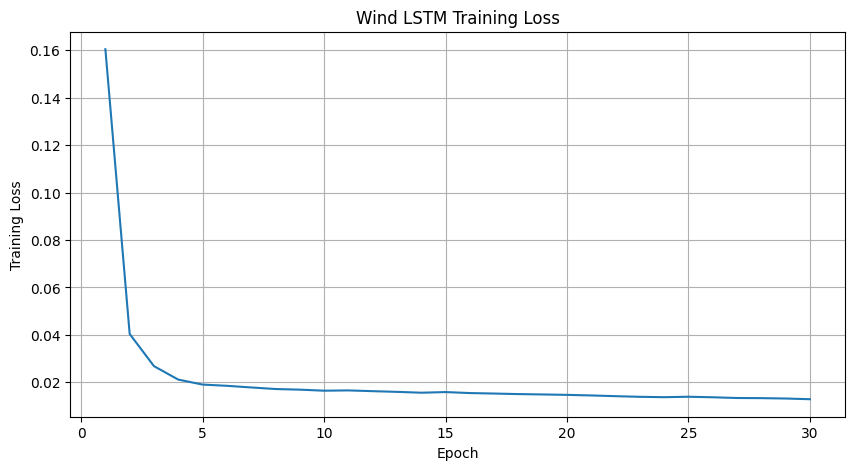

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Wind LSTM Training Loss")

plt.grid(True)
plt.show()

In [23]:
model.eval()

predictions = []
actuals = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        pred = model(X_batch)

        predictions.extend(pred.cpu().numpy())
        actuals.extend(y_batch.numpy())

predictions = np.array(predictions)
actuals = np.array(actuals)

print("Predictions:", predictions.shape)
print("Actuals    :", actuals.shape)

Predictions: (8760,)
Actuals    : (8760,)


In [24]:
predictions_mw = target_scaler.inverse_transform(
    predictions.reshape(-1, 1)
).flatten()

actuals_mw = target_scaler.inverse_transform(
    actuals.reshape(-1, 1)
).flatten()

print("Predicted MW range:")
print(predictions_mw.min(), "→", predictions_mw.max())

print("\nActual MW range:")
print(actuals_mw.min(), "→", actuals_mw.max())

Predicted MW range:
190.84961 → 27018.023

Actual MW range:
168.65137 → 28264.504


In [25]:
mae = mean_absolute_error(
    actuals_mw,
    predictions_mw
)

rmse = np.sqrt(
    mean_squared_error(
        actuals_mw,
        predictions_mw
    )
)

r2 = r2_score(
    actuals_mw,
    predictions_mw
)

# Avoid division by zero for MAPE
epsilon = 1e-8

mape = np.mean(
    np.abs(
        (actuals_mw - predictions_mw) /
        np.maximum(np.abs(actuals_mw), epsilon)
    )
) * 100

print("===== WIND LSTM BASELINE =====")

print(f"MAE  : {mae:.4f} MW")
print(f"RMSE : {rmse:.4f} MW")
print(f"R²   : {r2:.4f}")
print(f"MAPE : {mape:.2f}%")

===== WIND LSTM BASELINE =====
MAE  : 609.8519 MW
RMSE : 804.0656 MW
R²   : 0.9861
MAPE : 6.18%


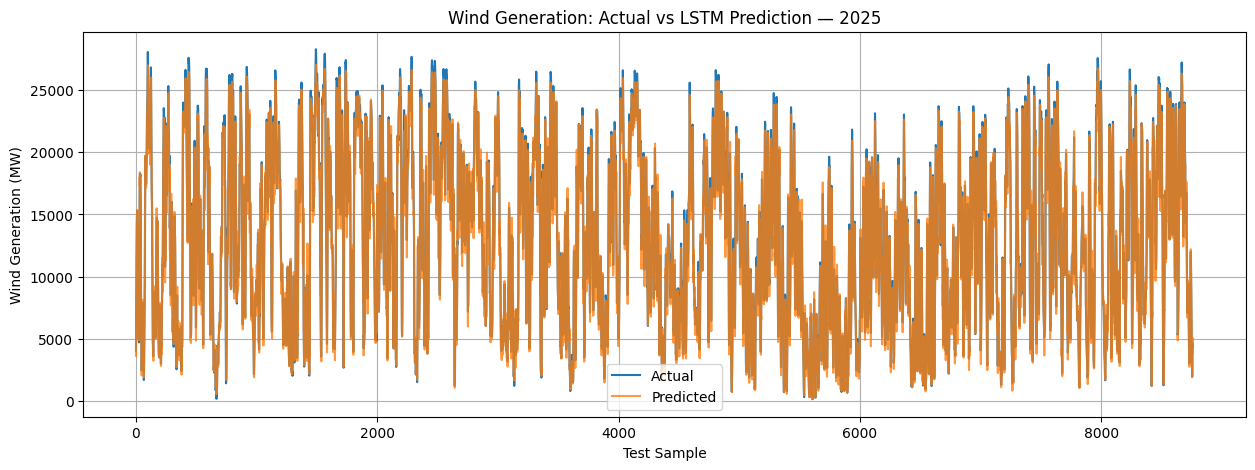

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    actuals_mw,
    label="Actual"
)

plt.plot(
    predictions_mw,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Test Sample")
plt.ylabel("Wind Generation (MW)")
plt.title("Wind Generation: Actual vs LSTM Prediction — 2025")

plt.legend()
plt.grid(True)

plt.show()

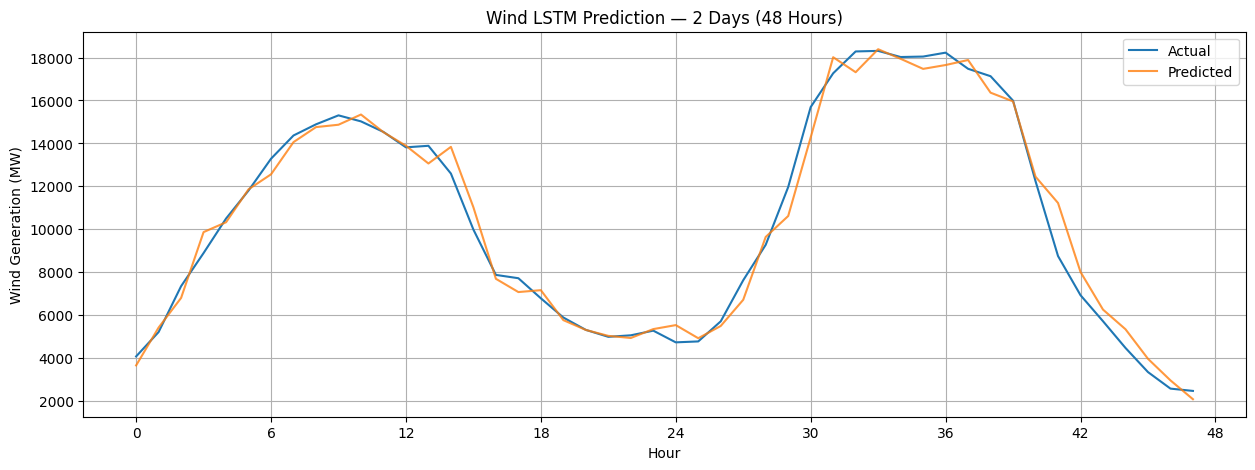

In [27]:
# Plot actual and predicted wind generation for 2 days (48 hours)

TWO_DAYS = 48

plt.figure(figsize=(15, 5))

plt.plot(
    actuals_mw[:TWO_DAYS],
    label="Actual"
)

plt.plot(
    predictions_mw[:TWO_DAYS],
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Hour")
plt.ylabel("Wind Generation (MW)")
plt.title("Wind LSTM Prediction — 2 Days (48 Hours)")

plt.legend()
plt.grid(True)

plt.xticks(
    range(0, TWO_DAYS + 1, 6)
)

plt.show()

# CNN-LSTM

In [28]:
# CNN-LSTM settings

LOOKBACK_CNN_LSTM = 6
BATCH_SIZE_CNN_LSTM = 64
EPOCHS_CNN_LSTM = 30

CNN_FILTERS_CNN_LSTM = 32
HIDDEN_SIZE_CNN_LSTM = 64
NUM_LAYERS_CNN_LSTM = 2
DROPOUT_CNN_LSTM = 0.2

LEARNING_RATE_CNN_LSTM = 0.001

In [29]:
# Create separate sequences for CNN-LSTM

# Scale the complete dataset using the scalers
# that were fitted only on the training data
features_scaled_cnn_lstm = feature_scaler.transform(
    df[FEATURES]
)

target_scaled_cnn_lstm = target_scaler.transform(
    df[[TARGET]]
).flatten()


X_train_seq_cnn_lstm = []
y_train_seq_cnn_lstm = []

X_test_seq_cnn_lstm = []
y_test_seq_cnn_lstm = []


# Create 6-hour input sequences
for i in range(LOOKBACK_CNN_LSTM, len(df)):

    X_sequence_cnn_lstm = features_scaled_cnn_lstm[
        i - LOOKBACK_CNN_LSTM:i
    ]

    y_value_cnn_lstm = target_scaled_cnn_lstm[i]

    # 2023–2024 → training
    if i < test_start_idx:

        X_train_seq_cnn_lstm.append(
            X_sequence_cnn_lstm
        )

        y_train_seq_cnn_lstm.append(
            y_value_cnn_lstm
        )

    # 2025 → testing
    else:

        X_test_seq_cnn_lstm.append(
            X_sequence_cnn_lstm
        )

        y_test_seq_cnn_lstm.append(
            y_value_cnn_lstm
        )


# Convert lists to NumPy arrays
X_train_seq_cnn_lstm = np.array(
    X_train_seq_cnn_lstm,
    dtype=np.float32
)

y_train_seq_cnn_lstm = np.array(
    y_train_seq_cnn_lstm,
    dtype=np.float32
)

X_test_seq_cnn_lstm = np.array(
    X_test_seq_cnn_lstm,
    dtype=np.float32
)

y_test_seq_cnn_lstm = np.array(
    y_test_seq_cnn_lstm,
    dtype=np.float32
)


print("CNN-LSTM sequence shapes")
print("--------------------------------")
print("X_train:", X_train_seq_cnn_lstm.shape)
print("y_train:", y_train_seq_cnn_lstm.shape)
print("X_test :", X_test_seq_cnn_lstm.shape)
print("y_test :", y_test_seq_cnn_lstm.shape)

CNN-LSTM sequence shapes
--------------------------------
X_train: (17531, 6, 13)
y_train: (17531,)
X_test : (8760, 6, 13)
y_test : (8760,)


In [30]:
# Dataset for CNN-LSTM

class WindCNNLSTMDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [31]:
# Create CNN-LSTM datasets

train_dataset_cnn_lstm = WindCNNLSTMDataset(
    X_train_seq_cnn_lstm,
    y_train_seq_cnn_lstm
)

test_dataset_cnn_lstm = WindCNNLSTMDataset(
    X_test_seq_cnn_lstm,
    y_test_seq_cnn_lstm
)


# Create DataLoaders

train_loader_cnn_lstm = DataLoader(
    train_dataset_cnn_lstm,
    batch_size=BATCH_SIZE_CNN_LSTM,
    shuffle=True
)

test_loader_cnn_lstm = DataLoader(
    test_dataset_cnn_lstm,
    batch_size=BATCH_SIZE_CNN_LSTM,
    shuffle=False
)


print("CNN-LSTM DataLoaders created successfully.")

CNN-LSTM DataLoaders created successfully.


In [32]:
# CNN-LSTM model

class WindCNNLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_filters,
        hidden_size,
        num_layers,
        dropout
    ):

        super(WindCNNLSTM, self).__init__()


        # CNN extracts local temporal patterns
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_filters,
            kernel_size=3,
            padding=1
        )


        self.relu = nn.ReLU()


        # LSTM learns temporal dependencies
        self.lstm = nn.LSTM(
            input_size=cnn_filters,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Final prediction layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )


    def forward(self, x):

        # Input:
        # (batch, time, features)

        # CNN requires:
        # (batch, features, time)

        x = x.permute(0, 2, 1)


        # CNN feature extraction
        x = self.conv1(x)

        x = self.relu(x)


        # Convert back for LSTM:
        # (batch, time, CNN features)

        x = x.permute(0, 2, 1)


        # LSTM
        lstm_output, _ = self.lstm(x)


        # Take the final timestep
        x = lstm_output[:, -1, :]


        # Final prediction
        x = self.fc(x)


        return x.squeeze(1)

In [33]:
# Create CNN-LSTM model

model_cnn_lstm = WindCNNLSTM(
    input_size=len(FEATURES),
    cnn_filters=CNN_FILTERS_CNN_LSTM,
    hidden_size=HIDDEN_SIZE_CNN_LSTM,
    num_layers=NUM_LAYERS_CNN_LSTM,
    dropout=DROPOUT_CNN_LSTM
).to(device)


print(model_cnn_lstm)

WindCNNLSTM(
  (conv1): Conv1d(13, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [34]:
# Count trainable parameters

parameters_cnn_lstm = sum(
    p.numel()
    for p in model_cnn_lstm.parameters()
    if p.requires_grad
)

print(
    f"CNN-LSTM trainable parameters: "
    f"{parameters_cnn_lstm:,}"
)

CNN-LSTM trainable parameters: 59,713


In [35]:
# Loss function and optimizer

criterion_cnn_lstm = nn.MSELoss()

optimizer_cnn_lstm = torch.optim.Adam(
    model_cnn_lstm.parameters(),
    lr=LEARNING_RATE_CNN_LSTM
)

In [36]:
# Train CNN-LSTM

def train_cnn_lstm_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_cnn_lstm = []


    for epoch in range(epochs):

        model.train()

        running_loss_cnn_lstm = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear previous gradients
            optimizer.zero_grad()


            # Forward pass
            predictions = model(X_batch)


            # Calculate loss
            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation
            loss.backward()


            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights
            optimizer.step()


            running_loss_cnn_lstm += loss.item()


        epoch_loss_cnn_lstm = (
            running_loss_cnn_lstm
            / len(train_loader)
        )


        losses_cnn_lstm.append(
            epoch_loss_cnn_lstm
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_cnn_lstm:.6f}"
        )


    return losses_cnn_lstm

In [37]:
# Train CNN-LSTM

training_losses_cnn_lstm = train_cnn_lstm_model(
    model=model_cnn_lstm,
    train_loader=train_loader_cnn_lstm,
    criterion=criterion_cnn_lstm,
    optimizer=optimizer_cnn_lstm,
    epochs=EPOCHS_CNN_LSTM
)

Epoch [01/30] Loss: 0.167101
Epoch [02/30] Loss: 0.035944
Epoch [03/30] Loss: 0.027135
Epoch [04/30] Loss: 0.023480
Epoch [05/30] Loss: 0.020553
Epoch [06/30] Loss: 0.019305
Epoch [07/30] Loss: 0.017718
Epoch [08/30] Loss: 0.016805
Epoch [09/30] Loss: 0.016293
Epoch [10/30] Loss: 0.016074
Epoch [11/30] Loss: 0.015864
Epoch [12/30] Loss: 0.015250
Epoch [13/30] Loss: 0.015126
Epoch [14/30] Loss: 0.014590
Epoch [15/30] Loss: 0.014611
Epoch [16/30] Loss: 0.014388
Epoch [17/30] Loss: 0.014243
Epoch [18/30] Loss: 0.014201
Epoch [19/30] Loss: 0.013929
Epoch [20/30] Loss: 0.013628
Epoch [21/30] Loss: 0.013685
Epoch [22/30] Loss: 0.013682
Epoch [23/30] Loss: 0.013512
Epoch [24/30] Loss: 0.013194
Epoch [25/30] Loss: 0.012956
Epoch [26/30] Loss: 0.013055
Epoch [27/30] Loss: 0.012965
Epoch [28/30] Loss: 0.012770
Epoch [29/30] Loss: 0.012569
Epoch [30/30] Loss: 0.012677


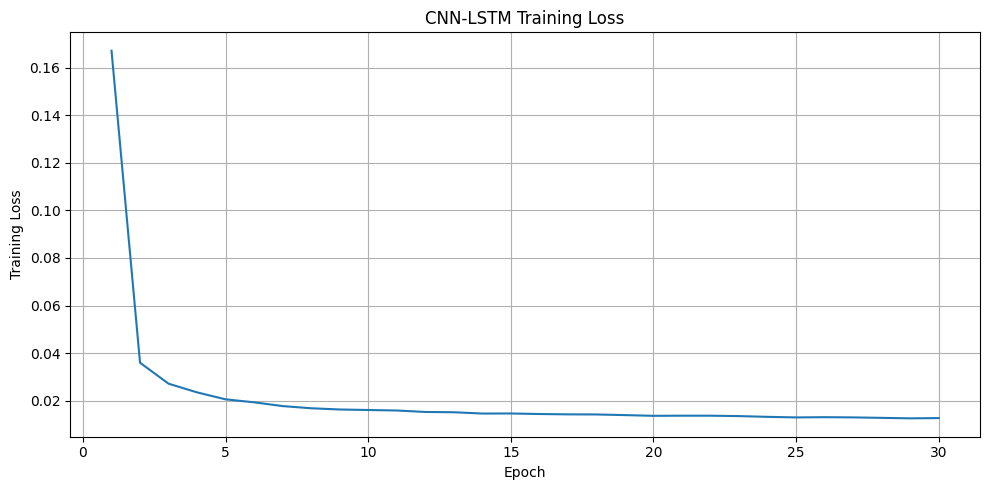

In [38]:
# Plot CNN-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS_CNN_LSTM + 1),
    training_losses_cnn_lstm
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN-LSTM Training Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
# Generate CNN-LSTM predictions on the 2025 test set

model_cnn_lstm.eval()

predictions_cnn_lstm_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_cnn_lstm:

        X_batch = X_batch.to(device)


        batch_predictions = model_cnn_lstm(
            X_batch
        )


        predictions_cnn_lstm_scaled.extend(
            batch_predictions.cpu().numpy()
        )


predictions_cnn_lstm_scaled = np.array(
    predictions_cnn_lstm_scaled
)


print(
    "Number of CNN-LSTM predictions:",
    len(predictions_cnn_lstm_scaled)
)

Number of CNN-LSTM predictions: 8760


In [40]:
# Convert CNN-LSTM predictions back to MW

predictions_cnn_lstm_mw = (
    target_scaler.inverse_transform(
        predictions_cnn_lstm_scaled.reshape(-1, 1)
    )
    .flatten()
)


# Convert actual values back to MW

actuals_cnn_lstm_mw = (
    target_scaler.inverse_transform(
        y_test_seq_cnn_lstm.reshape(-1, 1)
    )
    .flatten()
)


print(
    "Predicted MW range:"
)

print(
    f"{predictions_cnn_lstm_mw.min():.4f}"
    f" → "
    f"{predictions_cnn_lstm_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_cnn_lstm_mw.min():.4f}"
    f" → "
    f"{actuals_cnn_lstm_mw.max():.4f}"
)

Predicted MW range:
386.3008 → 26838.4297

Actual MW range:
168.6514 → 28264.5039


In [41]:
# Calculate CNN-LSTM performance

mae_cnn_lstm = mean_absolute_error(
    actuals_cnn_lstm_mw,
    predictions_cnn_lstm_mw
)


rmse_cnn_lstm = np.sqrt(
    mean_squared_error(
        actuals_cnn_lstm_mw,
        predictions_cnn_lstm_mw
    )
)


r2_cnn_lstm = r2_score(
    actuals_cnn_lstm_mw,
    predictions_cnn_lstm_mw
)


mape_cnn_lstm = np.mean(
    np.abs(
        (
            actuals_cnn_lstm_mw
            - predictions_cnn_lstm_mw
        )
        / actuals_cnn_lstm_mw
    )
) * 100


print("===== CNN-LSTM RESULTS =====")

print(
    f"MAE  : {mae_cnn_lstm:.2f} MW"
)

print(
    f"RMSE : {rmse_cnn_lstm:.2f} MW"
)

print(
    f"R²   : {r2_cnn_lstm:.4f}"
)

print(
    f"MAPE : {mape_cnn_lstm:.2f}%"
)

===== CNN-LSTM RESULTS =====
MAE  : 591.70 MW
RMSE : 796.27 MW
R²   : 0.9863
MAPE : 6.14%


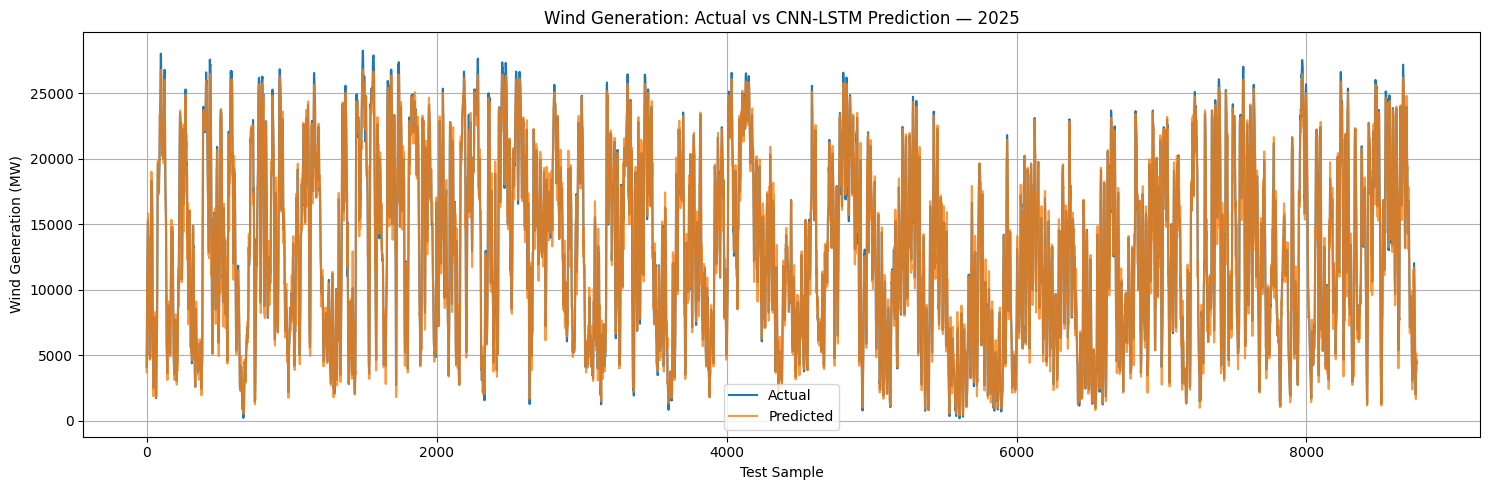

In [42]:
# Full 2025 actual vs predicted

plt.figure(figsize=(15, 5))

plt.plot(
    actuals_cnn_lstm_mw,
    label="Actual"
)

plt.plot(
    predictions_cnn_lstm_mw,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Test Sample")
plt.ylabel("Wind Generation (MW)")

plt.title(
    "Wind Generation: Actual vs CNN-LSTM Prediction — 2025"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

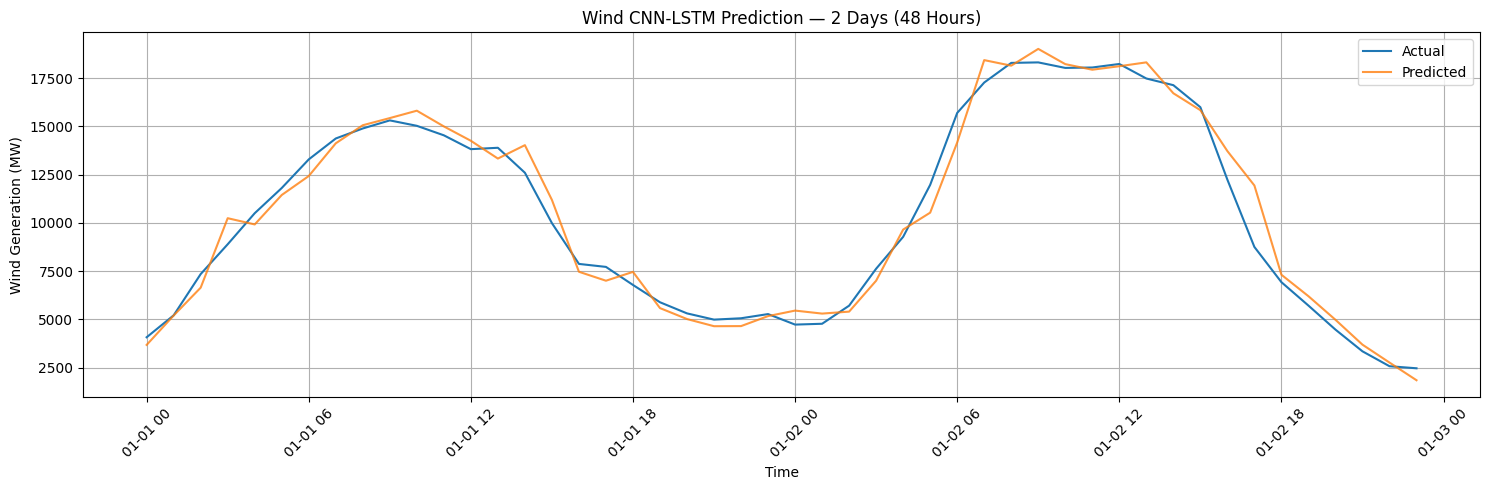

In [43]:
# CNN-LSTM prediction for the first 48 hours

TWO_DAYS_CNN_LSTM = 48


test_timestamps_cnn_lstm = df.loc[
    test_start_idx:
    test_start_idx + len(actuals_cnn_lstm_mw) - 1,
    "Datetime_UTC"
].reset_index(drop=True)


plt.figure(figsize=(15, 5))


plt.plot(
    test_timestamps_cnn_lstm[
        :TWO_DAYS_CNN_LSTM
    ],
    actuals_cnn_lstm_mw[
        :TWO_DAYS_CNN_LSTM
    ],
    label="Actual"
)


plt.plot(
    test_timestamps_cnn_lstm[
        :TWO_DAYS_CNN_LSTM
    ],
    predictions_cnn_lstm_mw[
        :TWO_DAYS_CNN_LSTM
    ],
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")
plt.ylabel("Wind Generation (MW)")

plt.title(
    "Wind CNN-LSTM Prediction — 2 Days (48 Hours)"
)

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Attention - LSTM Hybrid

In [44]:
# Attention-LSTM settings

LOOKBACK_ATTENTION_LSTM = 6
BATCH_SIZE_ATTENTION_LSTM = 64
EPOCHS_ATTENTION_LSTM = 30

HIDDEN_SIZE_ATTENTION_LSTM = 64
NUM_LAYERS_ATTENTION_LSTM = 2
DROPOUT_ATTENTION_LSTM = 0.2

LEARNING_RATE_ATTENTION_LSTM = 0.001

In [45]:
# Create separate sequences for Attention-LSTM

features_scaled_attention_lstm = feature_scaler.transform(
    df[FEATURES]
)

target_scaled_attention_lstm = target_scaler.transform(
    df[[TARGET]]
).flatten()


X_train_seq_attention_lstm = []
y_train_seq_attention_lstm = []

X_test_seq_attention_lstm = []
y_test_seq_attention_lstm = []


# Create 6-hour sequences

for i in range(LOOKBACK_ATTENTION_LSTM, len(df)):

    X_sequence_attention_lstm = features_scaled_attention_lstm[
        i - LOOKBACK_ATTENTION_LSTM:i
    ]

    y_value_attention_lstm = target_scaled_attention_lstm[i]


    # 2023–2024 training data
    if i < test_start_idx:

        X_train_seq_attention_lstm.append(
            X_sequence_attention_lstm
        )

        y_train_seq_attention_lstm.append(
            y_value_attention_lstm
        )


    # 2025 test data
    else:

        X_test_seq_attention_lstm.append(
            X_sequence_attention_lstm
        )

        y_test_seq_attention_lstm.append(
            y_value_attention_lstm
        )


# Convert to NumPy arrays

X_train_seq_attention_lstm = np.array(
    X_train_seq_attention_lstm,
    dtype=np.float32
)

y_train_seq_attention_lstm = np.array(
    y_train_seq_attention_lstm,
    dtype=np.float32
)

X_test_seq_attention_lstm = np.array(
    X_test_seq_attention_lstm,
    dtype=np.float32
)

y_test_seq_attention_lstm = np.array(
    y_test_seq_attention_lstm,
    dtype=np.float32
)


print("Attention-LSTM sequence shapes")
print("------------------------------------")

print(
    "X_train:",
    X_train_seq_attention_lstm.shape
)

print(
    "y_train:",
    y_train_seq_attention_lstm.shape
)

print(
    "X_test :",
    X_test_seq_attention_lstm.shape
)

print(
    "y_test :",
    y_test_seq_attention_lstm.shape
)

Attention-LSTM sequence shapes
------------------------------------
X_train: (17531, 6, 13)
y_train: (17531,)
X_test : (8760, 6, 13)
y_test : (8760,)


In [46]:
# Dataset for Attention-LSTM

class WindAttentionLSTMDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )


    def __len__(self):

        return len(self.X)


    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [47]:
# Create Attention-LSTM datasets

train_dataset_attention_lstm = WindAttentionLSTMDataset(
    X_train_seq_attention_lstm,
    y_train_seq_attention_lstm
)

test_dataset_attention_lstm = WindAttentionLSTMDataset(
    X_test_seq_attention_lstm,
    y_test_seq_attention_lstm
)


# Create DataLoaders

train_loader_attention_lstm = DataLoader(
    train_dataset_attention_lstm,
    batch_size=BATCH_SIZE_ATTENTION_LSTM,
    shuffle=True
)

test_loader_attention_lstm = DataLoader(
    test_dataset_attention_lstm,
    batch_size=BATCH_SIZE_ATTENTION_LSTM,
    shuffle=False
)


print(
    "Attention-LSTM DataLoaders created successfully."
)

Attention-LSTM DataLoaders created successfully.


In [48]:
# Attention-LSTM model

class WindAttentionLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        dropout
    ):

        super(WindAttentionLSTM, self).__init__()


        # LSTM extracts temporal information
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Attention layer
        self.attention = nn.Sequential(

            nn.Linear(
                hidden_size,
                hidden_size
            ),

            nn.Tanh(),

            nn.Linear(
                hidden_size,
                1
            )
        )


        # Final prediction layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )


    def forward(self, x):

        # LSTM output:
        # (batch, time, hidden_size)

        lstm_output, _ = self.lstm(x)


        # Calculate attention scores
        attention_scores = self.attention(
            lstm_output
        )


        # Convert scores into weights
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )


        # Weighted combination of all time steps
        context_vector = torch.sum(
            attention_weights * lstm_output,
            dim=1
        )


        # Final prediction
        output = self.fc(
            context_vector
        )


        return output.squeeze(1)

In [49]:
# Create Attention-LSTM model

model_attention_lstm = WindAttentionLSTM(
    input_size=len(FEATURES),
    hidden_size=HIDDEN_SIZE_ATTENTION_LSTM,
    num_layers=NUM_LAYERS_ATTENTION_LSTM,
    dropout=DROPOUT_ATTENTION_LSTM
).to(device)


print(model_attention_lstm)

WindAttentionLSTM(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [50]:
# Count trainable parameters

parameters_attention_lstm = sum(
    p.numel()
    for p in model_attention_lstm.parameters()
    if p.requires_grad
)

print(
    f"Attention-LSTM trainable parameters: "
    f"{parameters_attention_lstm:,}"
)

Attention-LSTM trainable parameters: 57,794


In [51]:
# Loss function and optimizer

criterion_attention_lstm = nn.MSELoss()

optimizer_attention_lstm = torch.optim.Adam(
    model_attention_lstm.parameters(),
    lr=LEARNING_RATE_ATTENTION_LSTM
)

In [52]:
# Train Attention-LSTM

def train_attention_lstm_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_attention_lstm = []


    for epoch in range(epochs):

        model.train()

        running_loss_attention_lstm = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear gradients
            optimizer.zero_grad()


            # Forward pass
            predictions = model(X_batch)


            # Calculate loss
            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation
            loss.backward()


            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights
            optimizer.step()


            running_loss_attention_lstm += loss.item()


        epoch_loss_attention_lstm = (
            running_loss_attention_lstm
            / len(train_loader)
        )


        losses_attention_lstm.append(
            epoch_loss_attention_lstm
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_attention_lstm:.6f}"
        )


    return losses_attention_lstm

In [53]:
# Train Attention-LSTM for exactly 30 epochs

training_losses_attention_lstm = train_attention_lstm_model(
    model=model_attention_lstm,
    train_loader=train_loader_attention_lstm,
    criterion=criterion_attention_lstm,
    optimizer=optimizer_attention_lstm,
    epochs=EPOCHS_ATTENTION_LSTM
)

Epoch [01/30] Loss: 0.210296
Epoch [02/30] Loss: 0.039967
Epoch [03/30] Loss: 0.025843
Epoch [04/30] Loss: 0.021047
Epoch [05/30] Loss: 0.018784
Epoch [06/30] Loss: 0.018106
Epoch [07/30] Loss: 0.017325
Epoch [08/30] Loss: 0.017208
Epoch [09/30] Loss: 0.016683
Epoch [10/30] Loss: 0.016697
Epoch [11/30] Loss: 0.016165
Epoch [12/30] Loss: 0.016308
Epoch [13/30] Loss: 0.016155
Epoch [14/30] Loss: 0.016031
Epoch [15/30] Loss: 0.015768
Epoch [16/30] Loss: 0.015636
Epoch [17/30] Loss: 0.015651
Epoch [18/30] Loss: 0.015289
Epoch [19/30] Loss: 0.015357
Epoch [20/30] Loss: 0.015232
Epoch [21/30] Loss: 0.015025
Epoch [22/30] Loss: 0.014996
Epoch [23/30] Loss: 0.014349
Epoch [24/30] Loss: 0.014671
Epoch [25/30] Loss: 0.014291
Epoch [26/30] Loss: 0.014246
Epoch [27/30] Loss: 0.013869
Epoch [28/30] Loss: 0.013953
Epoch [29/30] Loss: 0.013744
Epoch [30/30] Loss: 0.013596


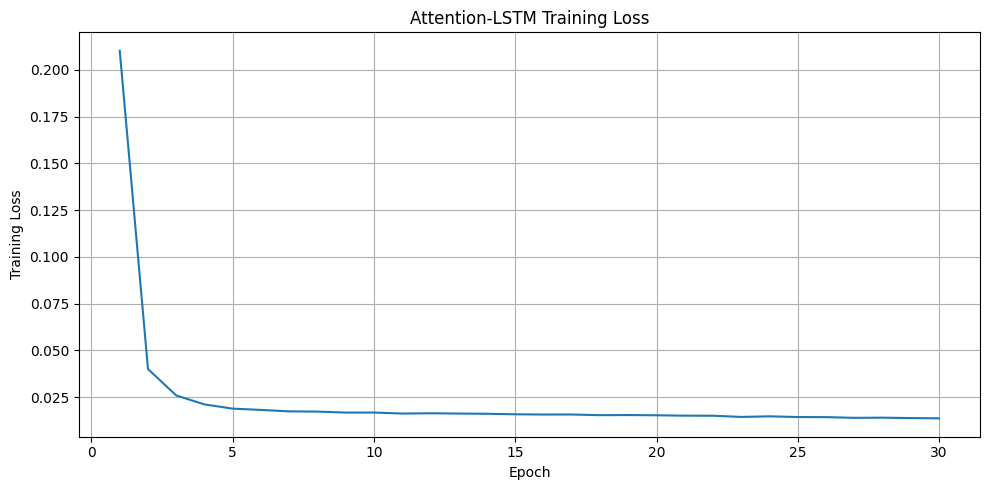

In [54]:
# Plot Attention-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_ATTENTION_LSTM + 1
    ),
    training_losses_attention_lstm
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Attention-LSTM Training Loss"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [55]:
# Generate Attention-LSTM predictions

model_attention_lstm.eval()

predictions_attention_lstm_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_attention_lstm:

        X_batch = X_batch.to(device)


        batch_predictions = model_attention_lstm(
            X_batch
        )


        predictions_attention_lstm_scaled.extend(
            batch_predictions.cpu().numpy()
        )


predictions_attention_lstm_scaled = np.array(
    predictions_attention_lstm_scaled
)


print(
    "Number of Attention-LSTM predictions:",
    len(predictions_attention_lstm_scaled)
)

Number of Attention-LSTM predictions: 8760


In [56]:
# Convert predictions back to MW

predictions_attention_lstm_mw = (
    target_scaler.inverse_transform(
        predictions_attention_lstm_scaled.reshape(-1, 1)
    )
    .flatten()
)


# Convert actual values back to MW

actuals_attention_lstm_mw = (
    target_scaler.inverse_transform(
        y_test_seq_attention_lstm.reshape(-1, 1)
    )
    .flatten()
)


print(
    "Predicted MW range:"
)

print(
    f"{predictions_attention_lstm_mw.min():.4f}"
    f" → "
    f"{predictions_attention_lstm_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_attention_lstm_mw.min():.4f}"
    f" → "
    f"{actuals_attention_lstm_mw.max():.4f}"
)

Predicted MW range:
598.4727 → 27388.2305

Actual MW range:
168.6514 → 28264.5039


In [57]:
# Calculate Attention-LSTM performance

mae_attention_lstm = mean_absolute_error(
    actuals_attention_lstm_mw,
    predictions_attention_lstm_mw
)


rmse_attention_lstm = np.sqrt(
    mean_squared_error(
        actuals_attention_lstm_mw,
        predictions_attention_lstm_mw
    )
)


r2_attention_lstm = r2_score(
    actuals_attention_lstm_mw,
    predictions_attention_lstm_mw
)


mape_attention_lstm = np.mean(
    np.abs(
        (
            actuals_attention_lstm_mw
            - predictions_attention_lstm_mw
        )
        / actuals_attention_lstm_mw
    )
) * 100


print("===== ATTENTION-LSTM RESULTS =====")

print(
    f"MAE  : {mae_attention_lstm:.2f} MW"
)

print(
    f"RMSE : {rmse_attention_lstm:.2f} MW"
)

print(
    f"R²   : {r2_attention_lstm:.4f}"
)

print(
    f"MAPE : {mape_attention_lstm:.2f}%"
)

===== ATTENTION-LSTM RESULTS =====
MAE  : 608.79 MW
RMSE : 810.53 MW
R²   : 0.9859
MAPE : 7.00%


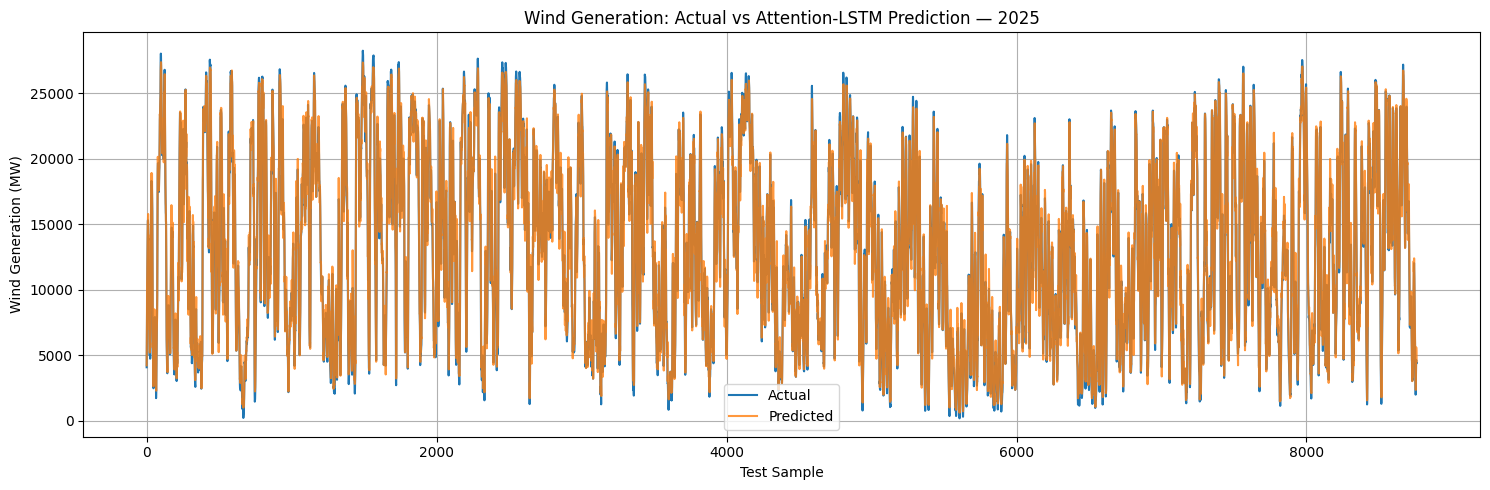

In [58]:
# Full 2025 actual vs predicted

plt.figure(figsize=(15, 5))

plt.plot(
    actuals_attention_lstm_mw,
    label="Actual"
)

plt.plot(
    predictions_attention_lstm_mw,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Test Sample")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind Generation: Actual vs Attention-LSTM Prediction — 2025"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

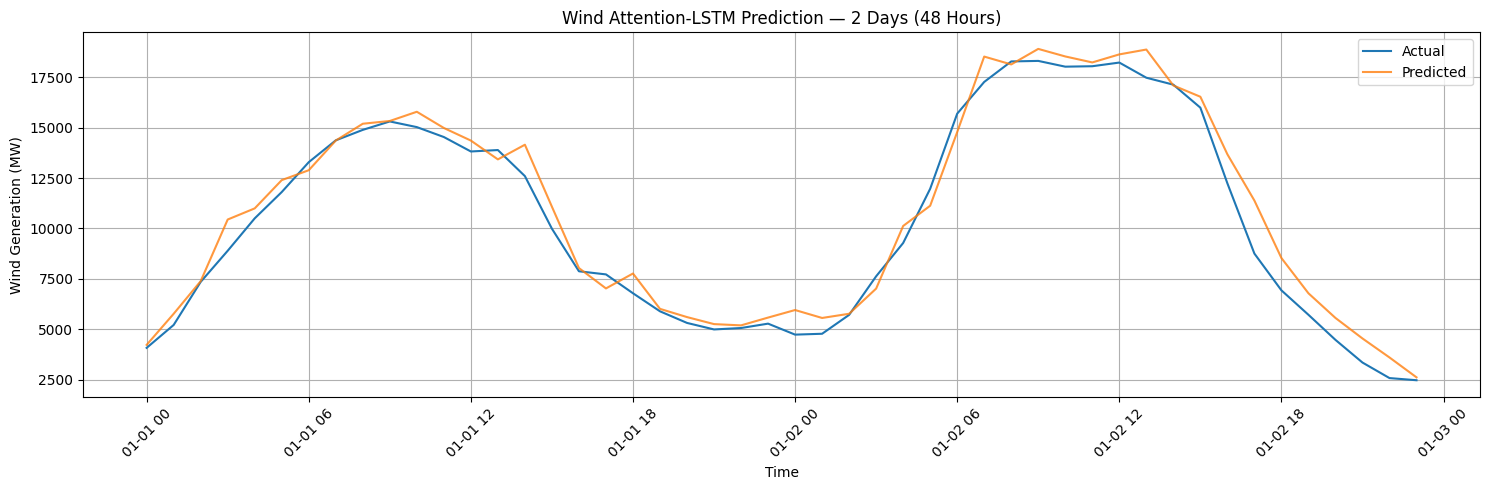

In [59]:
# Attention-LSTM prediction for the first 48 hours

TWO_DAYS_ATTENTION_LSTM = 48


test_timestamps_attention_lstm = df.loc[
    test_start_idx:
    test_start_idx + len(actuals_attention_lstm_mw) - 1,
    "Datetime_UTC"
].reset_index(drop=True)


plt.figure(figsize=(15, 5))


plt.plot(
    test_timestamps_attention_lstm[
        :TWO_DAYS_ATTENTION_LSTM
    ],
    actuals_attention_lstm_mw[
        :TWO_DAYS_ATTENTION_LSTM
    ],
    label="Actual"
)


plt.plot(
    test_timestamps_attention_lstm[
        :TWO_DAYS_ATTENTION_LSTM
    ],
    predictions_attention_lstm_mw[
        :TWO_DAYS_ATTENTION_LSTM
    ],
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind Attention-LSTM Prediction — 2 Days (48 Hours)"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# Residual-LSTM

In [60]:
# Residual-LSTM settings

LOOKBACK_RESIDUAL_LSTM = 6
BATCH_SIZE_RESIDUAL_LSTM = 64
EPOCHS_RESIDUAL_LSTM = 30

HIDDEN_SIZE_RESIDUAL_LSTM = 64
NUM_LAYERS_RESIDUAL_LSTM = 2
DROPOUT_RESIDUAL_LSTM = 0.2

LEARNING_RATE_RESIDUAL_LSTM = 0.001

In [61]:
# Create separate sequences for Residual-LSTM

features_scaled_residual_lstm = feature_scaler.transform(
    df[FEATURES]
)

target_scaled_residual_lstm = target_scaler.transform(
    df[[TARGET]]
).flatten()


X_train_seq_residual_lstm = []
y_train_seq_residual_lstm = []

X_test_seq_residual_lstm = []
y_test_seq_residual_lstm = []


# Create 6-hour sequences

for i in range(
    LOOKBACK_RESIDUAL_LSTM,
    len(df)
):

    X_sequence_residual_lstm = features_scaled_residual_lstm[
        i - LOOKBACK_RESIDUAL_LSTM:i
    ]

    y_value_residual_lstm = target_scaled_residual_lstm[i]


    # 2023–2024 training data
    if i < test_start_idx:

        X_train_seq_residual_lstm.append(
            X_sequence_residual_lstm
        )

        y_train_seq_residual_lstm.append(
            y_value_residual_lstm
        )


    # 2025 testing data
    else:

        X_test_seq_residual_lstm.append(
            X_sequence_residual_lstm
        )

        y_test_seq_residual_lstm.append(
            y_value_residual_lstm
        )


# Convert to NumPy arrays

X_train_seq_residual_lstm = np.array(
    X_train_seq_residual_lstm,
    dtype=np.float32
)

y_train_seq_residual_lstm = np.array(
    y_train_seq_residual_lstm,
    dtype=np.float32
)

X_test_seq_residual_lstm = np.array(
    X_test_seq_residual_lstm,
    dtype=np.float32
)

y_test_seq_residual_lstm = np.array(
    y_test_seq_residual_lstm,
    dtype=np.float32
)


print("Residual-LSTM sequence shapes")
print("------------------------------------")

print(
    "X_train:",
    X_train_seq_residual_lstm.shape
)

print(
    "y_train:",
    y_train_seq_residual_lstm.shape
)

print(
    "X_test :",
    X_test_seq_residual_lstm.shape
)

print(
    "y_test :",
    y_test_seq_residual_lstm.shape
)

Residual-LSTM sequence shapes
------------------------------------
X_train: (17531, 6, 13)
y_train: (17531,)
X_test : (8760, 6, 13)
y_test : (8760,)


In [62]:
# Dataset for Residual-LSTM

class WindResidualLSTMDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )


    def __len__(self):

        return len(self.X)


    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [63]:
# Create Residual-LSTM datasets

train_dataset_residual_lstm = WindResidualLSTMDataset(
    X_train_seq_residual_lstm,
    y_train_seq_residual_lstm
)

test_dataset_residual_lstm = WindResidualLSTMDataset(
    X_test_seq_residual_lstm,
    y_test_seq_residual_lstm
)


# Create DataLoaders

train_loader_residual_lstm = DataLoader(
    train_dataset_residual_lstm,
    batch_size=BATCH_SIZE_RESIDUAL_LSTM,
    shuffle=True
)

test_loader_residual_lstm = DataLoader(
    test_dataset_residual_lstm,
    batch_size=BATCH_SIZE_RESIDUAL_LSTM,
    shuffle=False
)


print(
    "Residual-LSTM DataLoaders created successfully."
)

Residual-LSTM DataLoaders created successfully.


In [64]:
# Residual-LSTM model

class WindResidualLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        dropout
    ):

        super(WindResidualLSTM, self).__init__()


        # Main LSTM branch
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Project input features to hidden dimension
        # so it can be added to the LSTM output
        self.residual_projection = nn.Linear(
            input_size,
            hidden_size
        )


        # Additional transformation
        self.residual_layer = nn.Linear(
            hidden_size,
            hidden_size
        )


        self.relu = nn.ReLU()


        # Final prediction layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )


    def forward(self, x):

        # Main LSTM branch
        lstm_output, _ = self.lstm(x)


        # Take final timestep
        lstm_last = lstm_output[:, -1, :]


        # Residual branch
        residual = x[:, -1, :]

        residual = self.residual_projection(
            residual
        )


        # Transform LSTM representation
        transformed = self.residual_layer(
            lstm_last
        )

        transformed = self.relu(
            transformed
        )


        # Residual connection
        combined = transformed + residual


        # Final prediction
        output = self.fc(
            combined
        )


        return output.squeeze(1)

In [65]:
# Create Residual-LSTM model

model_residual_lstm = WindResidualLSTM(
    input_size=len(FEATURES),
    hidden_size=HIDDEN_SIZE_RESIDUAL_LSTM,
    num_layers=NUM_LAYERS_RESIDUAL_LSTM,
    dropout=DROPOUT_RESIDUAL_LSTM
).to(device)


print(model_residual_lstm)

WindResidualLSTM(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (residual_projection): Linear(in_features=13, out_features=64, bias=True)
  (residual_layer): Linear(in_features=64, out_features=64, bias=True)
  (relu): ReLU()
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [66]:
# Count trainable parameters

parameters_residual_lstm = sum(
    p.numel()
    for p in model_residual_lstm.parameters()
    if p.requires_grad
)

print(
    f"Residual-LSTM trainable parameters: "
    f"{parameters_residual_lstm:,}"
)

Residual-LSTM trainable parameters: 58,625


In [67]:
# Loss function and optimizer

criterion_residual_lstm = nn.MSELoss()

optimizer_residual_lstm = torch.optim.Adam(
    model_residual_lstm.parameters(),
    lr=LEARNING_RATE_RESIDUAL_LSTM
)

In [68]:
# Train Residual-LSTM

def train_residual_lstm_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_residual_lstm = []


    for epoch in range(epochs):

        model.train()

        running_loss_residual_lstm = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear gradients
            optimizer.zero_grad()


            # Forward pass
            predictions = model(X_batch)


            # Calculate loss
            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation
            loss.backward()


            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights
            optimizer.step()


            running_loss_residual_lstm += loss.item()


        epoch_loss_residual_lstm = (
            running_loss_residual_lstm
            / len(train_loader)
        )


        losses_residual_lstm.append(
            epoch_loss_residual_lstm
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_residual_lstm:.6f}"
        )


    return losses_residual_lstm

In [69]:
# Train Residual-LSTM for exactly 30 epochs

training_losses_residual_lstm = train_residual_lstm_model(
    model=model_residual_lstm,
    train_loader=train_loader_residual_lstm,
    criterion=criterion_residual_lstm,
    optimizer=optimizer_residual_lstm,
    epochs=EPOCHS_RESIDUAL_LSTM
)

Epoch [01/30] Loss: 0.083446
Epoch [02/30] Loss: 0.021592
Epoch [03/30] Loss: 0.020073
Epoch [04/30] Loss: 0.019010
Epoch [05/30] Loss: 0.017920
Epoch [06/30] Loss: 0.016704
Epoch [07/30] Loss: 0.015250
Epoch [08/30] Loss: 0.014753
Epoch [09/30] Loss: 0.014414
Epoch [10/30] Loss: 0.013891
Epoch [11/30] Loss: 0.013555
Epoch [12/30] Loss: 0.012946
Epoch [13/30] Loss: 0.012588
Epoch [14/30] Loss: 0.012466
Epoch [15/30] Loss: 0.012043
Epoch [16/30] Loss: 0.011990
Epoch [17/30] Loss: 0.011868
Epoch [18/30] Loss: 0.011695
Epoch [19/30] Loss: 0.011610
Epoch [20/30] Loss: 0.011336
Epoch [21/30] Loss: 0.011399
Epoch [22/30] Loss: 0.011370
Epoch [23/30] Loss: 0.011172
Epoch [24/30] Loss: 0.010951
Epoch [25/30] Loss: 0.011013
Epoch [26/30] Loss: 0.010905
Epoch [27/30] Loss: 0.010802
Epoch [28/30] Loss: 0.010669
Epoch [29/30] Loss: 0.010565
Epoch [30/30] Loss: 0.010547


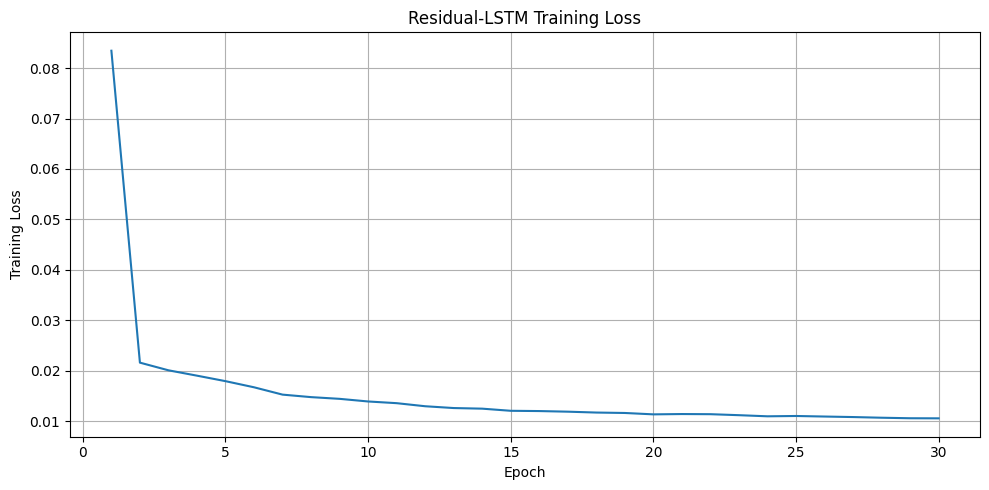

In [70]:
# Plot Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_LSTM + 1
    ),
    training_losses_residual_lstm
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Residual-LSTM Training Loss"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [71]:
# Generate Residual-LSTM predictions

model_residual_lstm.eval()

predictions_residual_lstm_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_residual_lstm:

        X_batch = X_batch.to(device)


        batch_predictions = model_residual_lstm(
            X_batch
        )


        predictions_residual_lstm_scaled.extend(
            batch_predictions.cpu().numpy()
        )


predictions_residual_lstm_scaled = np.array(
    predictions_residual_lstm_scaled
)


print(
    "Number of Residual-LSTM predictions:",
    len(predictions_residual_lstm_scaled)
)

Number of Residual-LSTM predictions: 8760


In [72]:
# Convert predictions back to MW

predictions_residual_lstm_mw = (
    target_scaler.inverse_transform(
        predictions_residual_lstm_scaled.reshape(-1, 1)
    )
    .flatten()
)


# Convert actual values back to MW

actuals_residual_lstm_mw = (
    target_scaler.inverse_transform(
        y_test_seq_residual_lstm.reshape(-1, 1)
    )
    .flatten()
)


print(
    "Predicted MW range:"
)

print(
    f"{predictions_residual_lstm_mw.min():.4f}"
    f" → "
    f"{predictions_residual_lstm_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_residual_lstm_mw.min():.4f}"
    f" → "
    f"{actuals_residual_lstm_mw.max():.4f}"
)

Predicted MW range:
68.1084 → 28103.2559

Actual MW range:
168.6514 → 28264.5039


In [73]:
# Calculate Residual-LSTM performance

mae_residual_lstm = mean_absolute_error(
    actuals_residual_lstm_mw,
    predictions_residual_lstm_mw
)


rmse_residual_lstm = np.sqrt(
    mean_squared_error(
        actuals_residual_lstm_mw,
        predictions_residual_lstm_mw
    )
)


r2_residual_lstm = r2_score(
    actuals_residual_lstm_mw,
    predictions_residual_lstm_mw
)


mape_residual_lstm = np.mean(
    np.abs(
        (
            actuals_residual_lstm_mw
            - predictions_residual_lstm_mw
        )
        / actuals_residual_lstm_mw
    )
) * 100


print("===== RESIDUAL-LSTM RESULTS =====")

print(
    f"MAE  : {mae_residual_lstm:.2f} MW"
)

print(
    f"RMSE : {rmse_residual_lstm:.2f} MW"
)

print(
    f"R²   : {r2_residual_lstm:.4f}"
)

print(
    f"MAPE : {mape_residual_lstm:.2f}%"
)

===== RESIDUAL-LSTM RESULTS =====
MAE  : 576.79 MW
RMSE : 778.79 MW
R²   : 0.9869
MAPE : 5.96%


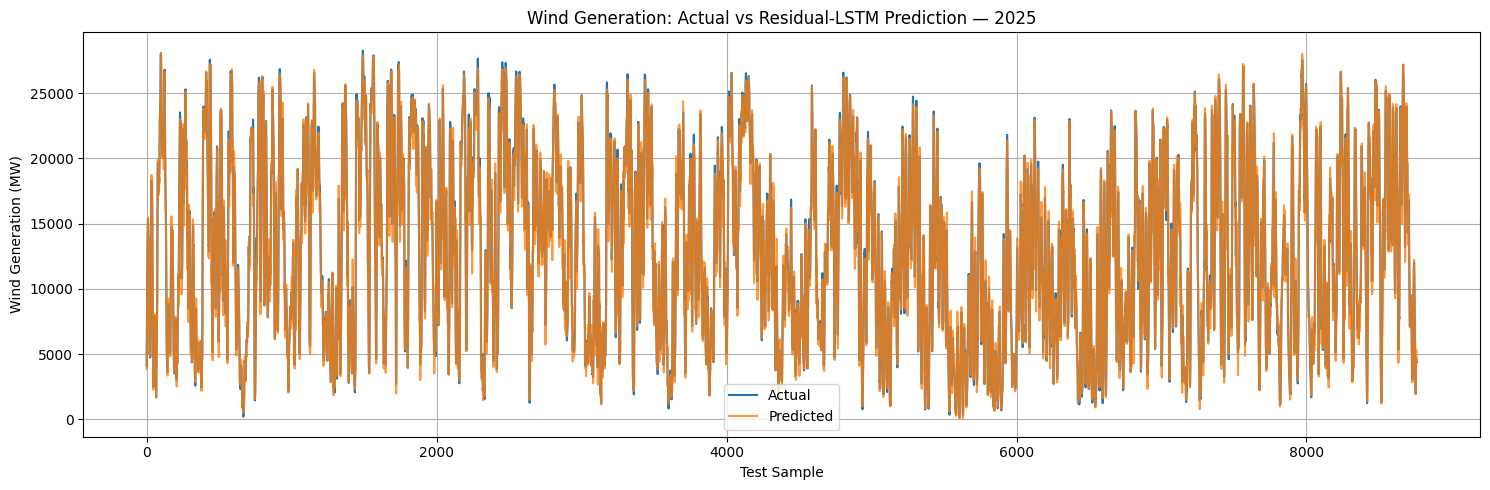

In [74]:
# Full 2025 actual vs predicted

plt.figure(figsize=(15, 5))

plt.plot(
    actuals_residual_lstm_mw,
    label="Actual"
)

plt.plot(
    predictions_residual_lstm_mw,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Test Sample")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind Generation: Actual vs Residual-LSTM Prediction — 2025"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

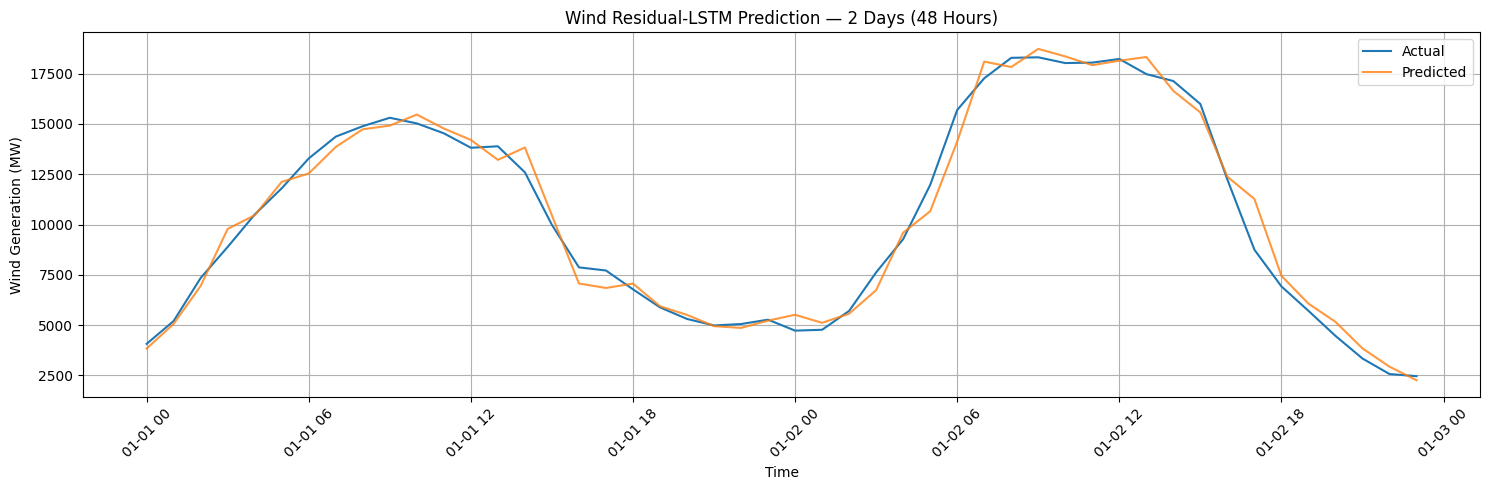

In [75]:
# Residual-LSTM prediction for the first 48 hours

TWO_DAYS_RESIDUAL_LSTM = 48


test_timestamps_residual_lstm = df.loc[
    test_start_idx:
    test_start_idx + len(actuals_residual_lstm_mw) - 1,
    "Datetime_UTC"
].reset_index(drop=True)


plt.figure(figsize=(15, 5))


plt.plot(
    test_timestamps_residual_lstm[
        :TWO_DAYS_RESIDUAL_LSTM
    ],
    actuals_residual_lstm_mw[
        :TWO_DAYS_RESIDUAL_LSTM
    ],
    label="Actual"
)


plt.plot(
    test_timestamps_residual_lstm[
        :TWO_DAYS_RESIDUAL_LSTM
    ],
    predictions_residual_lstm_mw[
        :TWO_DAYS_RESIDUAL_LSTM
    ],
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind Residual-LSTM Prediction — 2 Days (48 Hours)"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# CNN-LSTM-Attention

In [76]:
# CNN-LSTM-Attention settings

LOOKBACK_CNN_ATTENTION = 6
BATCH_SIZE_CNN_ATTENTION = 64
EPOCHS_CNN_ATTENTION = 30

CNN_FILTERS_CNN_ATTENTION = 32
CNN_KERNEL_CNN_ATTENTION = 3

HIDDEN_SIZE_CNN_ATTENTION = 64
NUM_LAYERS_CNN_ATTENTION = 2
DROPOUT_CNN_ATTENTION = 0.2

LEARNING_RATE_CNN_ATTENTION = 0.001

In [77]:
# Create separate sequences for CNN-LSTM-Attention

features_scaled_cnn_attention = feature_scaler.transform(
    df[FEATURES]
)

target_scaled_cnn_attention = target_scaler.transform(
    df[[TARGET]]
).flatten()


X_train_seq_cnn_attention = []
y_train_seq_cnn_attention = []

X_test_seq_cnn_attention = []
y_test_seq_cnn_attention = []


# Create 6-hour sequences

for i in range(
    LOOKBACK_CNN_ATTENTION,
    len(df)
):

    X_sequence_cnn_attention = features_scaled_cnn_attention[
        i - LOOKBACK_CNN_ATTENTION:i
    ]

    y_value_cnn_attention = target_scaled_cnn_attention[i]


    # 2023–2024 → training
    if i < test_start_idx:

        X_train_seq_cnn_attention.append(
            X_sequence_cnn_attention
        )

        y_train_seq_cnn_attention.append(
            y_value_cnn_attention
        )


    # 2025 → testing
    else:

        X_test_seq_cnn_attention.append(
            X_sequence_cnn_attention
        )

        y_test_seq_cnn_attention.append(
            y_value_cnn_attention
        )


# Convert to NumPy arrays

X_train_seq_cnn_attention = np.array(
    X_train_seq_cnn_attention,
    dtype=np.float32
)

y_train_seq_cnn_attention = np.array(
    y_train_seq_cnn_attention,
    dtype=np.float32
)

X_test_seq_cnn_attention = np.array(
    X_test_seq_cnn_attention,
    dtype=np.float32
)

y_test_seq_cnn_attention = np.array(
    y_test_seq_cnn_attention,
    dtype=np.float32
)


print("CNN-LSTM-Attention sequence shapes")
print("----------------------------------------")

print(
    "X_train:",
    X_train_seq_cnn_attention.shape
)

print(
    "y_train:",
    y_train_seq_cnn_attention.shape
)

print(
    "X_test :",
    X_test_seq_cnn_attention.shape
)

print(
    "y_test :",
    y_test_seq_cnn_attention.shape
)

CNN-LSTM-Attention sequence shapes
----------------------------------------
X_train: (17531, 6, 13)
y_train: (17531,)
X_test : (8760, 6, 13)
y_test : (8760,)


In [78]:
# Dataset for CNN-LSTM-Attention

class WindCNNAttentionDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )


    def __len__(self):

        return len(self.X)


    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [79]:
# Create CNN-LSTM-Attention datasets

train_dataset_cnn_attention = WindCNNAttentionDataset(
    X_train_seq_cnn_attention,
    y_train_seq_cnn_attention
)

test_dataset_cnn_attention = WindCNNAttentionDataset(
    X_test_seq_cnn_attention,
    y_test_seq_cnn_attention
)


# Create DataLoaders

train_loader_cnn_attention = DataLoader(
    train_dataset_cnn_attention,
    batch_size=BATCH_SIZE_CNN_ATTENTION,
    shuffle=True
)

test_loader_cnn_attention = DataLoader(
    test_dataset_cnn_attention,
    batch_size=BATCH_SIZE_CNN_ATTENTION,
    shuffle=False
)


print(
    "CNN-LSTM-Attention DataLoaders created successfully."
)

CNN-LSTM-Attention DataLoaders created successfully.


In [80]:
# CNN-LSTM-Attention model

class WindCNNAttention(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_filters,
        cnn_kernel,
        hidden_size,
        num_layers,
        dropout
    ):

        super(WindCNNAttention, self).__init__()


        # CNN extracts short-term local patterns
        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_filters,
            kernel_size=cnn_kernel,
            padding=cnn_kernel // 2
        )


        self.relu = nn.ReLU()


        # LSTM learns temporal dependencies
        self.lstm = nn.LSTM(
            input_size=cnn_filters,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Attention calculates importance of each timestep
        self.attention = nn.Sequential(

            nn.Linear(
                hidden_size,
                hidden_size
            ),

            nn.Tanh(),

            nn.Linear(
                hidden_size,
                1
            )
        )


        # Final prediction layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )


    def forward(self, x):

        # Input:
        # (batch, time, features)


        # CNN expects:
        # (batch, features, time)

        x = x.permute(
            0, 2, 1
        )


        # CNN feature extraction

        x = self.conv1(x)

        x = self.relu(x)


        # Convert back to:
        # (batch, time, CNN features)

        x = x.permute(
            0, 2, 1
        )


        # LSTM

        lstm_output, _ = self.lstm(x)


        # Calculate attention scores
        attention_scores = self.attention(
            lstm_output
        )


        # Convert scores into weights

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )


        # Weighted temporal representation

        context_vector = torch.sum(
            attention_weights * lstm_output,
            dim=1
        )


        # Final prediction

        output = self.fc(
            context_vector
        )


        return output.squeeze(1)

In [81]:
# Create CNN-LSTM-Attention model

model_cnn_attention = WindCNNAttention(
    input_size=len(FEATURES),
    cnn_filters=CNN_FILTERS_CNN_ATTENTION,
    cnn_kernel=CNN_KERNEL_CNN_ATTENTION,
    hidden_size=HIDDEN_SIZE_CNN_ATTENTION,
    num_layers=NUM_LAYERS_CNN_ATTENTION,
    dropout=DROPOUT_CNN_ATTENTION
).to(device)


print(model_cnn_attention)

WindCNNAttention(
  (conv1): Conv1d(13, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [82]:
# Count trainable parameters

parameters_cnn_attention = sum(
    p.numel()
    for p in model_cnn_attention.parameters()
    if p.requires_grad
)

print(
    f"CNN-LSTM-Attention trainable parameters: "
    f"{parameters_cnn_attention:,}"
)

CNN-LSTM-Attention trainable parameters: 63,938


In [83]:
# Loss function and optimizer

criterion_cnn_attention = nn.MSELoss()

optimizer_cnn_attention = torch.optim.Adam(
    model_cnn_attention.parameters(),
    lr=LEARNING_RATE_CNN_ATTENTION
)

In [84]:
# Train CNN-LSTM-Attention

def train_cnn_attention_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_cnn_attention = []


    for epoch in range(epochs):

        model.train()

        running_loss_cnn_attention = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear gradients
            optimizer.zero_grad()


            # Forward pass
            predictions = model(
                X_batch
            )


            # Calculate loss
            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation
            loss.backward()


            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights
            optimizer.step()


            running_loss_cnn_attention += loss.item()


        epoch_loss_cnn_attention = (
            running_loss_cnn_attention
            / len(train_loader)
        )


        losses_cnn_attention.append(
            epoch_loss_cnn_attention
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_cnn_attention:.6f}"
        )


    return losses_cnn_attention

In [85]:
# Train CNN-LSTM-Attention for exactly 30 epochs

training_losses_cnn_attention = train_cnn_attention_model(
    model=model_cnn_attention,
    train_loader=train_loader_cnn_attention,
    criterion=criterion_cnn_attention,
    optimizer=optimizer_cnn_attention,
    epochs=EPOCHS_CNN_ATTENTION
)

Epoch [01/30] Loss: 0.196077
Epoch [02/30] Loss: 0.038436
Epoch [03/30] Loss: 0.028102
Epoch [04/30] Loss: 0.024621
Epoch [05/30] Loss: 0.022816
Epoch [06/30] Loss: 0.019971
Epoch [07/30] Loss: 0.019095
Epoch [08/30] Loss: 0.018072
Epoch [09/30] Loss: 0.017374
Epoch [10/30] Loss: 0.016650
Epoch [11/30] Loss: 0.016393
Epoch [12/30] Loss: 0.015798
Epoch [13/30] Loss: 0.015626
Epoch [14/30] Loss: 0.015520
Epoch [15/30] Loss: 0.015117
Epoch [16/30] Loss: 0.014873
Epoch [17/30] Loss: 0.014754
Epoch [18/30] Loss: 0.014633
Epoch [19/30] Loss: 0.014667
Epoch [20/30] Loss: 0.014425
Epoch [21/30] Loss: 0.014302
Epoch [22/30] Loss: 0.013928
Epoch [23/30] Loss: 0.014054
Epoch [24/30] Loss: 0.013866
Epoch [25/30] Loss: 0.013874
Epoch [26/30] Loss: 0.013350
Epoch [27/30] Loss: 0.013606
Epoch [28/30] Loss: 0.013461
Epoch [29/30] Loss: 0.013032
Epoch [30/30] Loss: 0.013181


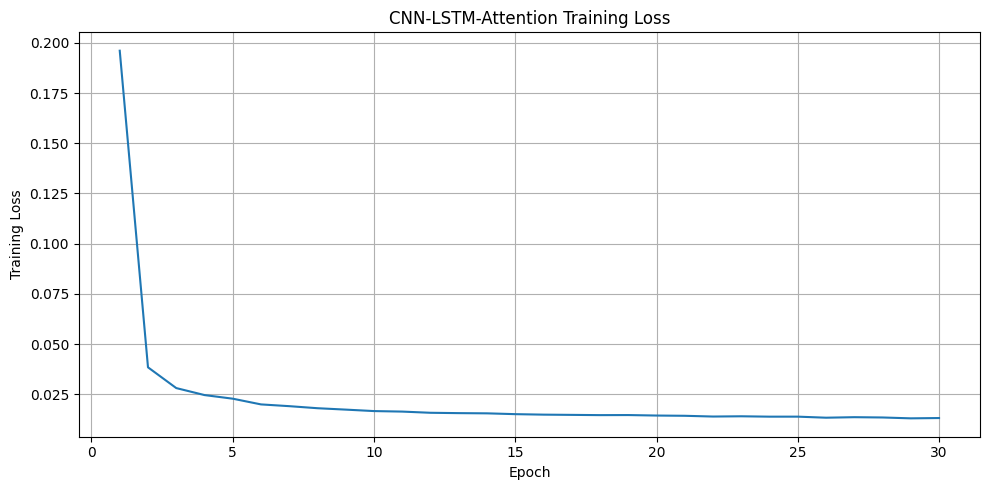

In [86]:
# Plot CNN-LSTM-Attention training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_CNN_ATTENTION + 1
    ),
    training_losses_cnn_attention
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "CNN-LSTM-Attention Training Loss"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [87]:
# Generate CNN-LSTM-Attention predictions

model_cnn_attention.eval()

predictions_cnn_attention_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_cnn_attention:

        X_batch = X_batch.to(device)


        batch_predictions = model_cnn_attention(
            X_batch
        )


        predictions_cnn_attention_scaled.extend(
            batch_predictions.cpu().numpy()
        )


predictions_cnn_attention_scaled = np.array(
    predictions_cnn_attention_scaled
)


print(
    "Number of CNN-LSTM-Attention predictions:",
    len(predictions_cnn_attention_scaled)
)

Number of CNN-LSTM-Attention predictions: 8760


In [88]:
# Convert predictions back to MW

predictions_cnn_attention_mw = (
    target_scaler.inverse_transform(
        predictions_cnn_attention_scaled.reshape(-1, 1)
    )
    .flatten()
)


# Convert actual values back to MW

actuals_cnn_attention_mw = (
    target_scaler.inverse_transform(
        y_test_seq_cnn_attention.reshape(-1, 1)
    )
    .flatten()
)


print(
    "Predicted MW range:"
)

print(
    f"{predictions_cnn_attention_mw.min():.4f}"
    f" → "
    f"{predictions_cnn_attention_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_cnn_attention_mw.min():.4f}"
    f" → "
    f"{actuals_cnn_attention_mw.max():.4f}"
)

Predicted MW range:
101.6924 → 26738.6484

Actual MW range:
168.6514 → 28264.5039


In [89]:
# Calculate CNN-LSTM-Attention performance

mae_cnn_attention = mean_absolute_error(
    actuals_cnn_attention_mw,
    predictions_cnn_attention_mw
)


rmse_cnn_attention = np.sqrt(
    mean_squared_error(
        actuals_cnn_attention_mw,
        predictions_cnn_attention_mw
    )
)


r2_cnn_attention = r2_score(
    actuals_cnn_attention_mw,
    predictions_cnn_attention_mw
)


mape_cnn_attention = np.mean(
    np.abs(
        (
            actuals_cnn_attention_mw
            - predictions_cnn_attention_mw
        )
        / actuals_cnn_attention_mw
    )
) * 100


print("===== CNN-LSTM-ATTENTION RESULTS =====")

print(
    f"MAE  : {mae_cnn_attention:.2f} MW"
)

print(
    f"RMSE : {rmse_cnn_attention:.2f} MW"
)

print(
    f"R²   : {r2_cnn_attention:.4f}"
)

print(
    f"MAPE : {mape_cnn_attention:.2f}%"
)

===== CNN-LSTM-ATTENTION RESULTS =====
MAE  : 635.91 MW
RMSE : 835.37 MW
R²   : 0.9850
MAPE : 6.49%


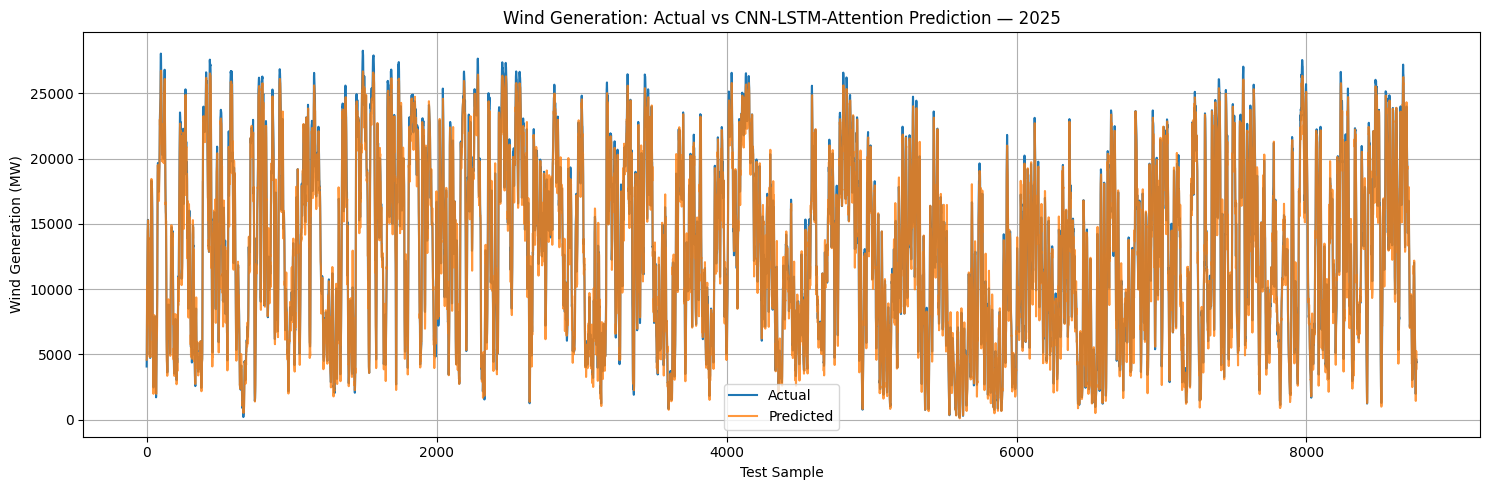

In [90]:
# Full 2025 actual vs predicted

plt.figure(figsize=(15, 5))

plt.plot(
    actuals_cnn_attention_mw,
    label="Actual"
)

plt.plot(
    predictions_cnn_attention_mw,
    label="Predicted",
    alpha=0.8
)

plt.xlabel("Test Sample")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind Generation: Actual vs CNN-LSTM-Attention Prediction — 2025"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

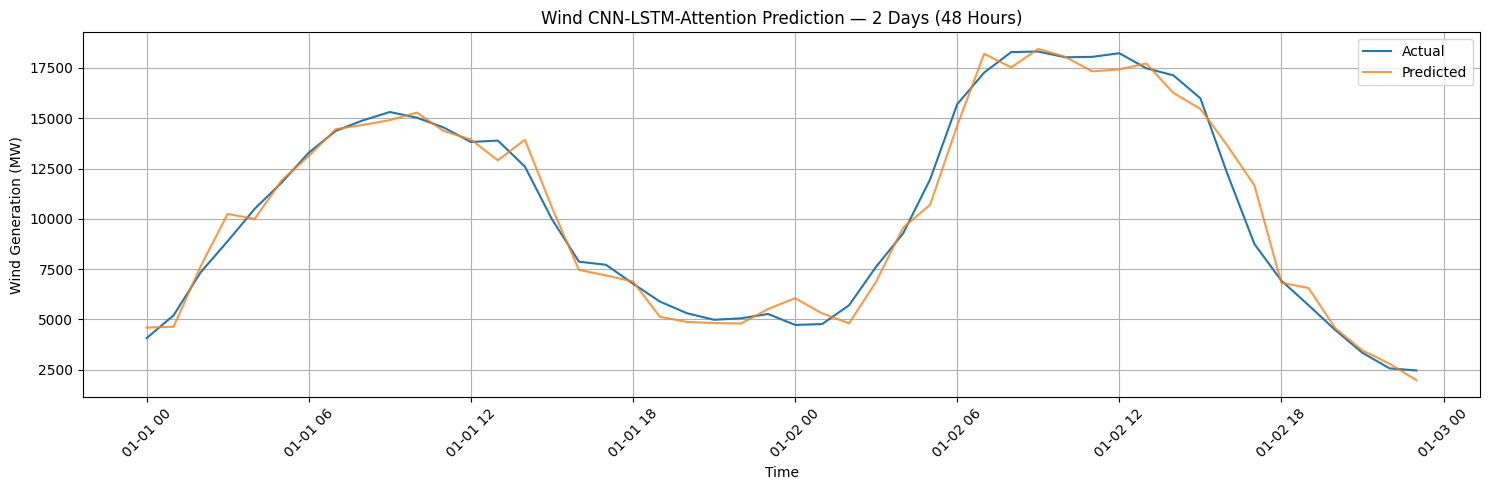

In [91]:
# CNN-LSTM-Attention prediction for the first 48 hours

TWO_DAYS_CNN_ATTENTION = 48


test_timestamps_cnn_attention = df.loc[
    test_start_idx:
    test_start_idx + len(actuals_cnn_attention_mw) - 1,
    "Datetime_UTC"
].reset_index(drop=True)


plt.figure(figsize=(15, 5))


plt.plot(
    test_timestamps_cnn_attention[
        :TWO_DAYS_CNN_ATTENTION
    ],
    actuals_cnn_attention_mw[
        :TWO_DAYS_CNN_ATTENTION
    ],
    label="Actual"
)


plt.plot(
    test_timestamps_cnn_attention[
        :TWO_DAYS_CNN_ATTENTION
    ],
    predictions_cnn_attention_mw[
        :TWO_DAYS_CNN_ATTENTION
    ],
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Wind CNN-LSTM-Attention Prediction — 2 Days (48 Hours)"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# 6-hour forecasting

# Base LSTM

In [92]:
# 6-hour Residual-LSTM settings

LOOKBACK_RESIDUAL_6H = 6
FORECAST_HORIZON_RESIDUAL_6H = 6

BATCH_SIZE_RESIDUAL_6H = 64
EPOCHS_RESIDUAL_6H = 30

HIDDEN_SIZE_RESIDUAL_6H = 64
NUM_LAYERS_RESIDUAL_6H = 2
DROPOUT_RESIDUAL_6H = 0.2

LEARNING_RATE_RESIDUAL_6H = 0.001

In [93]:
# Create separate sequences for 6-hour forecasting

features_scaled_residual_6h = feature_scaler.transform(
    df[FEATURES]
)

target_scaled_residual_6h = target_scaler.transform(
    df[[TARGET]]
).flatten()


X_train_seq_residual_6h = []
y_train_seq_residual_6h = []

X_test_seq_residual_6h = []
y_test_seq_residual_6h = []


# Create input-output sequences

for i in range(
    LOOKBACK_RESIDUAL_6H,
    len(df) - FORECAST_HORIZON_RESIDUAL_6H + 1
):

    # Previous 6 hours
    X_sequence_residual_6h = features_scaled_residual_6h[
        i - LOOKBACK_RESIDUAL_6H:i
    ]


    # Next 6 hours
    y_sequence_residual_6h = target_scaled_residual_6h[
        i:i + FORECAST_HORIZON_RESIDUAL_6H
    ]


    # Training sample:
    # all 6 target hours must belong to 2023-2024

    if i + FORECAST_HORIZON_RESIDUAL_6H <= test_start_idx:

        X_train_seq_residual_6h.append(
            X_sequence_residual_6h
        )

        y_train_seq_residual_6h.append(
            y_sequence_residual_6h
        )


    # Test sample:
    # all 6 target hours belong to 2025

    elif i >= test_start_idx:

        X_test_seq_residual_6h.append(
            X_sequence_residual_6h
        )

        y_test_seq_residual_6h.append(
            y_sequence_residual_6h
        )


# Convert to NumPy arrays

X_train_seq_residual_6h = np.array(
    X_train_seq_residual_6h,
    dtype=np.float32
)

y_train_seq_residual_6h = np.array(
    y_train_seq_residual_6h,
    dtype=np.float32
)

X_test_seq_residual_6h = np.array(
    X_test_seq_residual_6h,
    dtype=np.float32
)

y_test_seq_residual_6h = np.array(
    y_test_seq_residual_6h,
    dtype=np.float32
)


print("6-hour Residual-LSTM sequence shapes")
print("----------------------------------------")

print(
    "X_train:",
    X_train_seq_residual_6h.shape
)

print(
    "y_train:",
    y_train_seq_residual_6h.shape
)

print(
    "X_test :",
    X_test_seq_residual_6h.shape
)

print(
    "y_test :",
    y_test_seq_residual_6h.shape
)

6-hour Residual-LSTM sequence shapes
----------------------------------------
X_train: (17526, 6, 13)
y_train: (17526, 6)
X_test : (8755, 6, 13)
y_test : (8755, 6)


In [94]:
# Dataset for 6-hour Residual-LSTM

class WindResidual6HDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )


    def __len__(self):

        return len(self.X)


    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [95]:
# Create 6-hour datasets

train_dataset_residual_6h = WindResidual6HDataset(
    X_train_seq_residual_6h,
    y_train_seq_residual_6h
)

test_dataset_residual_6h = WindResidual6HDataset(
    X_test_seq_residual_6h,
    y_test_seq_residual_6h
)


# Create DataLoaders

train_loader_residual_6h = DataLoader(
    train_dataset_residual_6h,
    batch_size=BATCH_SIZE_RESIDUAL_6H,
    shuffle=True
)

test_loader_residual_6h = DataLoader(
    test_dataset_residual_6h,
    batch_size=BATCH_SIZE_RESIDUAL_6H,
    shuffle=False
)


print(
    "6-hour Residual-LSTM DataLoaders created successfully."
)

6-hour Residual-LSTM DataLoaders created successfully.


In [96]:
# Residual-LSTM for direct 6-hour forecasting

class WindResidualLSTM6H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        dropout,
        forecast_horizon
    ):

        super(WindResidualLSTM6H, self).__init__()


        # Main LSTM branch
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Residual projection
        self.residual_projection = nn.Linear(
            input_size,
            hidden_size
        )


        # Additional transformation
        self.residual_layer = nn.Linear(
            hidden_size,
            hidden_size
        )


        self.relu = nn.ReLU()


        # Predict all 6 future hours directly
        self.fc = nn.Linear(
            hidden_size,
            forecast_horizon
        )


    def forward(self, x):

        # Main LSTM branch

        lstm_output, _ = self.lstm(x)


        # Representation from the last input timestep

        lstm_last = lstm_output[:, -1, :]


        # Residual branch

        residual = x[:, -1, :]

        residual = self.residual_projection(
            residual
        )


        # Transform LSTM representation

        transformed = self.residual_layer(
            lstm_last
        )

        transformed = self.relu(
            transformed
        )


        # Residual connection

        combined = transformed + residual


        # Six future predictions

        output = self.fc(
            combined
        )


        return output

In [97]:
# Create 6-hour Residual-LSTM

model_residual_6h = WindResidualLSTM6H(
    input_size=len(FEATURES),
    hidden_size=HIDDEN_SIZE_RESIDUAL_6H,
    num_layers=NUM_LAYERS_RESIDUAL_6H,
    dropout=DROPOUT_RESIDUAL_6H,
    forecast_horizon=FORECAST_HORIZON_RESIDUAL_6H
).to(device)


print(model_residual_6h)

WindResidualLSTM6H(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (residual_projection): Linear(in_features=13, out_features=64, bias=True)
  (residual_layer): Linear(in_features=64, out_features=64, bias=True)
  (relu): ReLU()
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [98]:
# Count trainable parameters

parameters_residual_6h = sum(
    p.numel()
    for p in model_residual_6h.parameters()
    if p.requires_grad
)

print(
    f"6-hour Residual-LSTM trainable parameters: "
    f"{parameters_residual_6h:,}"
)

6-hour Residual-LSTM trainable parameters: 58,950


In [99]:
# Loss function and optimizer

criterion_residual_6h = nn.MSELoss()

optimizer_residual_6h = torch.optim.Adam(
    model_residual_6h.parameters(),
    lr=LEARNING_RATE_RESIDUAL_6H
)

In [100]:
# Train 6-hour Residual-LSTM

def train_residual_6h_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_residual_6h = []


    for epoch in range(epochs):

        model.train()

        running_loss_residual_6h = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear gradients

            optimizer.zero_grad()


            # Forward pass

            predictions = model(
                X_batch
            )


            # Calculate loss

            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation

            loss.backward()


            # Prevent very large gradients

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights

            optimizer.step()


            running_loss_residual_6h += loss.item()


        epoch_loss_residual_6h = (
            running_loss_residual_6h
            / len(train_loader)
        )


        losses_residual_6h.append(
            epoch_loss_residual_6h
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_residual_6h:.6f}"
        )


    return losses_residual_6h

In [101]:
# Train 6-hour Residual-LSTM

training_losses_residual_6h = train_residual_6h_model(
    model=model_residual_6h,
    train_loader=train_loader_residual_6h,
    criterion=criterion_residual_6h,
    optimizer=optimizer_residual_6h,
    epochs=EPOCHS_RESIDUAL_6H
)

Epoch [01/30] Loss: 0.271991
Epoch [02/30] Loss: 0.162593
Epoch [03/30] Loss: 0.153925
Epoch [04/30] Loss: 0.147613
Epoch [05/30] Loss: 0.141866
Epoch [06/30] Loss: 0.136801
Epoch [07/30] Loss: 0.132575
Epoch [08/30] Loss: 0.129149
Epoch [09/30] Loss: 0.125534
Epoch [10/30] Loss: 0.122918
Epoch [11/30] Loss: 0.119597
Epoch [12/30] Loss: 0.116079
Epoch [13/30] Loss: 0.111878
Epoch [14/30] Loss: 0.109163
Epoch [15/30] Loss: 0.106539
Epoch [16/30] Loss: 0.102992
Epoch [17/30] Loss: 0.100525
Epoch [18/30] Loss: 0.097335
Epoch [19/30] Loss: 0.094232
Epoch [20/30] Loss: 0.090715
Epoch [21/30] Loss: 0.087252
Epoch [22/30] Loss: 0.084324
Epoch [23/30] Loss: 0.080758
Epoch [24/30] Loss: 0.078258
Epoch [25/30] Loss: 0.075406
Epoch [26/30] Loss: 0.073087
Epoch [27/30] Loss: 0.069676
Epoch [28/30] Loss: 0.068430
Epoch [29/30] Loss: 0.064340
Epoch [30/30] Loss: 0.062635


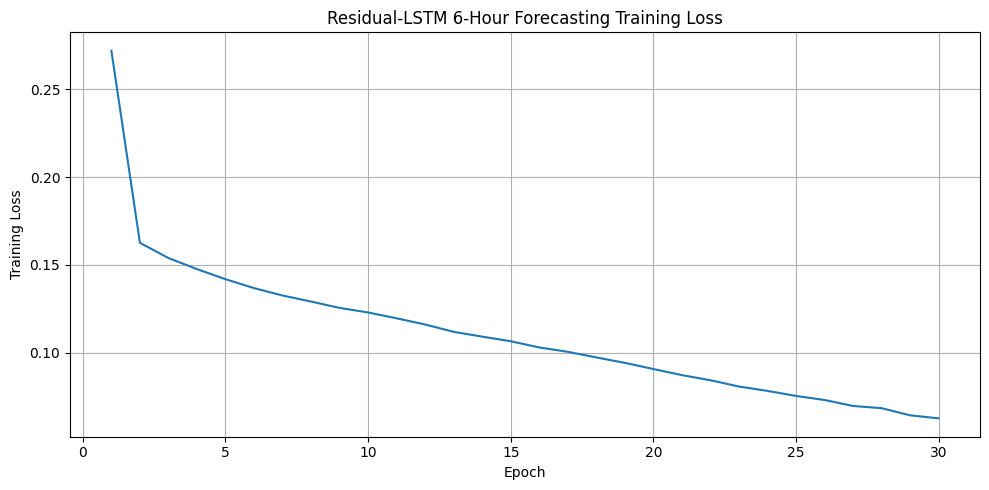

In [102]:
# Plot 6-hour Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_6H + 1
    ),
    training_losses_residual_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Residual-LSTM 6-Hour Forecasting Training Loss"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [103]:
# Generate 6-hour predictions

model_residual_6h.eval()

predictions_residual_6h_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_residual_6h:

        X_batch = X_batch.to(device)


        batch_predictions = model_residual_6h(
            X_batch
        )


        predictions_residual_6h_scaled.append(
            batch_predictions.cpu().numpy()
        )


predictions_residual_6h_scaled = np.concatenate(
    predictions_residual_6h_scaled,
    axis=0
)


print(
    "Prediction shape:",
    predictions_residual_6h_scaled.shape
)

Prediction shape: (8755, 6)


In [104]:
# Convert 6-hour predictions back to MW

predictions_residual_6h_mw = (
    target_scaler.inverse_transform(
        predictions_residual_6h_scaled.reshape(-1, 1)
    )
    .reshape(
        predictions_residual_6h_scaled.shape
    )
)


# Convert actual values back to MW

actuals_residual_6h_mw = (
    target_scaler.inverse_transform(
        y_test_seq_residual_6h.reshape(-1, 1)
    )
    .reshape(
        y_test_seq_residual_6h.shape
    )
)


print(
    "Prediction shape:",
    predictions_residual_6h_mw.shape
)

print(
    "Actual shape:",
    actuals_residual_6h_mw.shape
)


print(
    "\nPredicted MW range:"
)

print(
    f"{predictions_residual_6h_mw.min():.4f}"
    f" → "
    f"{predictions_residual_6h_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_residual_6h_mw.min():.4f}"
    f" → "
    f"{actuals_residual_6h_mw.max():.4f}"
)

Prediction shape: (8755, 6)
Actual shape: (8755, 6)

Predicted MW range:
-794.2607 → 28622.0566

Actual MW range:
168.6514 → 28264.5039


In [105]:
# Calculate overall 6-hour forecasting metrics

actuals_residual_6h_flat = (
    actuals_residual_6h_mw.flatten()
)

predictions_residual_6h_flat = (
    predictions_residual_6h_mw.flatten()
)


mae_residual_6h = mean_absolute_error(
    actuals_residual_6h_flat,
    predictions_residual_6h_flat
)


rmse_residual_6h = np.sqrt(
    mean_squared_error(
        actuals_residual_6h_flat,
        predictions_residual_6h_flat
    )
)


r2_residual_6h = r2_score(
    actuals_residual_6h_flat,
    predictions_residual_6h_flat
)


mape_residual_6h = np.mean(
    np.abs(
        (
            actuals_residual_6h_flat
            - predictions_residual_6h_flat
        )
        / actuals_residual_6h_flat
    )
) * 100


print("===== RESIDUAL-LSTM 6-HOUR RESULTS =====")

print(
    f"MAE  : {mae_residual_6h:.2f} MW"
)

print(
    f"RMSE : {rmse_residual_6h:.2f} MW"
)

print(
    f"R²   : {r2_residual_6h:.4f}"
)

print(
    f"MAPE : {mape_residual_6h:.2f}%"
)

===== RESIDUAL-LSTM 6-HOUR RESULTS =====
MAE  : 2086.77 MW
RMSE : 2977.77 MW
R²   : 0.8090
MAPE : 22.49%


In [106]:
# Calculate metrics separately for each forecast horizon

residual_6h_horizon_results = []


for horizon_index in range(
    FORECAST_HORIZON_RESIDUAL_6H
):

    actual_horizon = actuals_residual_6h_mw[
        :, horizon_index
    ]

    predicted_horizon = predictions_residual_6h_mw[
        :, horizon_index
    ]


    mae_horizon = mean_absolute_error(
        actual_horizon,
        predicted_horizon
    )


    rmse_horizon = np.sqrt(
        mean_squared_error(
            actual_horizon,
            predicted_horizon
        )
    )


    r2_horizon = r2_score(
        actual_horizon,
        predicted_horizon
    )


    mape_horizon = np.mean(
        np.abs(
            (
                actual_horizon
                - predicted_horizon
            )
            / actual_horizon
        )
    ) * 100


    residual_6h_horizon_results.append(
        {
            "Horizon": f"t+{horizon_index + 1}",
            "MAE_MW": mae_horizon,
            "RMSE_MW": rmse_horizon,
            "R2": r2_horizon,
            "MAPE_percent": mape_horizon
        }
    )


residual_6h_horizon_df = pd.DataFrame(
    residual_6h_horizon_results
)


print(
    residual_6h_horizon_df.to_string(
        index=False
    )
)

Horizon      MAE_MW     RMSE_MW       R2  MAPE_percent
    t+1  740.377502  987.140789 0.979012      7.791065
    t+2 1372.531982 1819.289422 0.928714     14.482548
    t+3 1925.189453 2553.057285 0.859618     20.133968
    t+4 2422.194336 3209.128698 0.778220     25.672752
    t+5 2856.320312 3772.682070 0.693532     30.973076
    t+6 3204.032959 4227.131415 0.615318     35.867203


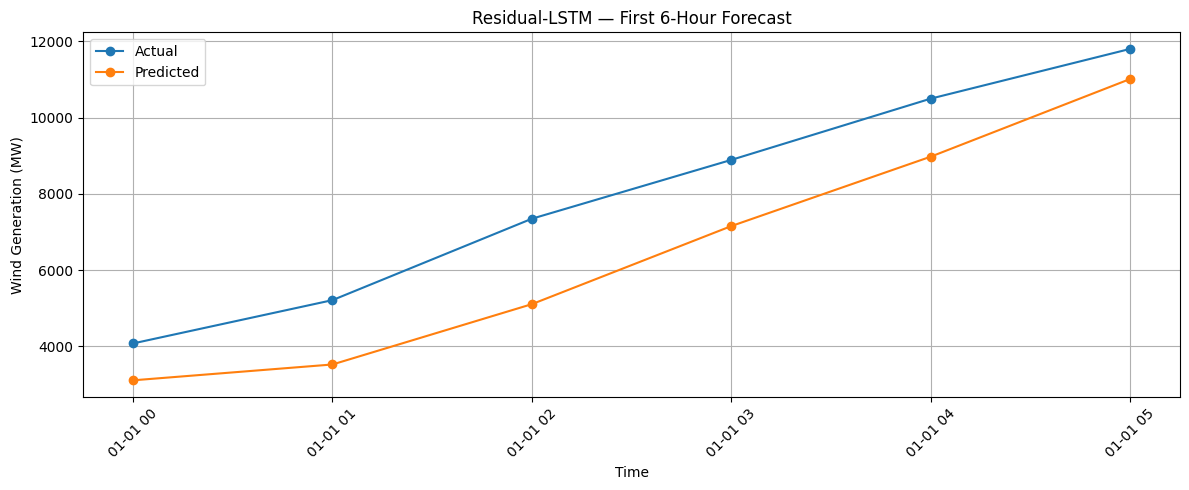

In [107]:
# Plot the first 6-hour forecast

first_forecast_timestamp_residual_6h = df.loc[
    test_start_idx,
    "Datetime_UTC"
]


forecast_timestamps_residual_6h = pd.date_range(
    start=first_forecast_timestamp_residual_6h,
    periods=FORECAST_HORIZON_RESIDUAL_6H,
    freq="h"
)


plt.figure(figsize=(12, 5))


plt.plot(
    forecast_timestamps_residual_6h,
    actuals_residual_6h_mw[0],
    marker="o",
    label="Actual"
)


plt.plot(
    forecast_timestamps_residual_6h,
    predictions_residual_6h_mw[0],
    marker="o",
    label="Predicted"
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Residual-LSTM — First 6-Hour Forecast"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

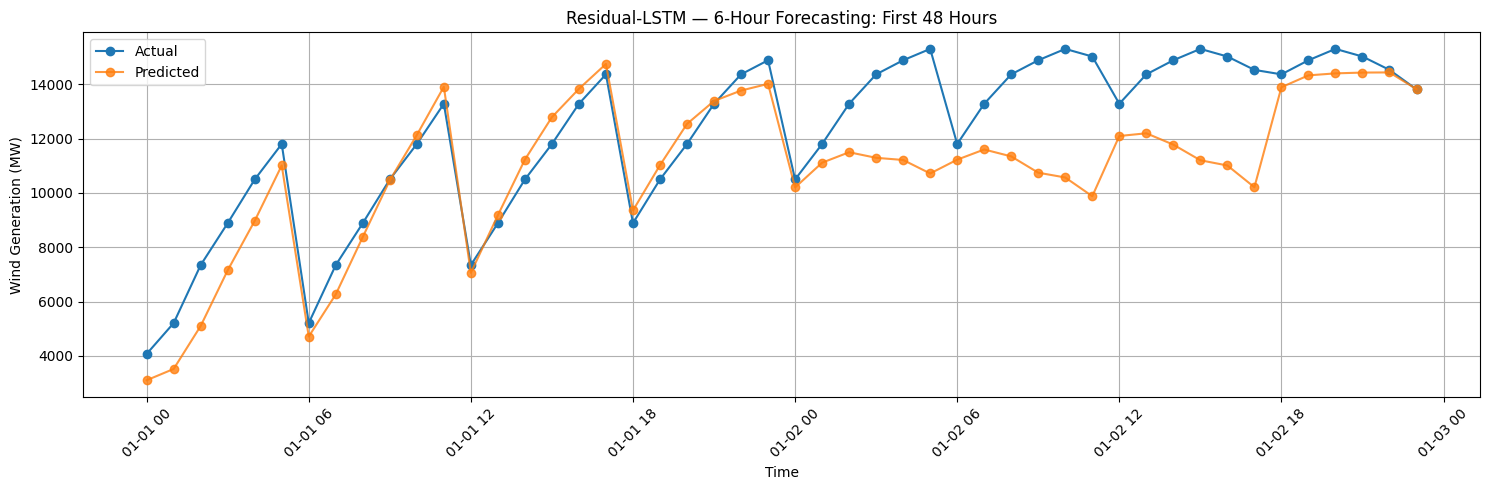

In [108]:
# Plot the first 48 hours using non-overlapping 6-hour forecasts

NUMBER_OF_48H_WINDOWS_RESIDUAL_6H = 8


actual_48h_residual_6h = (
    actuals_residual_6h_mw[
        :NUMBER_OF_48H_WINDOWS_RESIDUAL_6H
    ].reshape(-1)
)


predicted_48h_residual_6h = (
    predictions_residual_6h_mw[
        :NUMBER_OF_48H_WINDOWS_RESIDUAL_6H
    ].reshape(-1)
)


timestamps_48h_residual_6h = pd.date_range(
    start=df.loc[
        test_start_idx,
        "Datetime_UTC"
    ],
    periods=48,
    freq="h"
)


plt.figure(figsize=(15, 5))


plt.plot(
    timestamps_48h_residual_6h,
    actual_48h_residual_6h,
    marker="o",
    label="Actual"
)


plt.plot(
    timestamps_48h_residual_6h,
    predicted_48h_residual_6h,
    marker="o",
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Residual-LSTM — 6-Hour Forecasting: First 48 Hours"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# Residual -LSTM 

In [109]:
# Improved 6-hour Residual-LSTM settings

LOOKBACK_RESIDUAL_6H_24LB = 24
FORECAST_HORIZON_RESIDUAL_6H_24LB = 6

BATCH_SIZE_RESIDUAL_6H_24LB = 64
EPOCHS_RESIDUAL_6H_24LB = 30

HIDDEN_SIZE_RESIDUAL_6H_24LB = 64
NUM_LAYERS_RESIDUAL_6H_24LB = 2
DROPOUT_RESIDUAL_6H_24LB = 0.2

LEARNING_RATE_RESIDUAL_6H_24LB = 0.001

In [111]:
# Separate target scaler for the improved 6-hour model
# It keeps the target non-negative after inverse transformation.

from sklearn.preprocessing import MaxAbsScaler

target_scaler_residual_6h_24lb = MaxAbsScaler()


train_target_values_residual_6h_24lb = df.loc[
    df["Datetime_UTC"] < "2025-01-01",
    [TARGET]
]


target_scaler_residual_6h_24lb.fit(
    train_target_values_residual_6h_24lb
)


target_scaled_residual_6h_24lb = (
    target_scaler_residual_6h_24lb.transform(
        df[[TARGET]]
    )
    .flatten()
)


print("Target scaler fitted only on 2023–2024 training data.")

Target scaler fitted only on 2023–2024 training data.


In [112]:
# Create sequences using 24 hours of history
# to predict the next 6 hours.

features_scaled_residual_6h_24lb = feature_scaler.transform(
    df[FEATURES]
)


X_train_seq_residual_6h_24lb = []
y_train_seq_residual_6h_24lb = []

X_test_seq_residual_6h_24lb = []
y_test_seq_residual_6h_24lb = []


for i in range(
    LOOKBACK_RESIDUAL_6H_24LB,
    len(df) - FORECAST_HORIZON_RESIDUAL_6H_24LB + 1
):

    # Previous 24 hours
    X_sequence_residual_6h_24lb = (
        features_scaled_residual_6h_24lb[
            i - LOOKBACK_RESIDUAL_6H_24LB:i
        ]
    )


    # Next 6 hours
    y_sequence_residual_6h_24lb = (
        target_scaled_residual_6h_24lb[
            i:i + FORECAST_HORIZON_RESIDUAL_6H_24LB
        ]
    )


    # Training sample
    if (
        i + FORECAST_HORIZON_RESIDUAL_6H_24LB
        <= test_start_idx
    ):

        X_train_seq_residual_6h_24lb.append(
            X_sequence_residual_6h_24lb
        )

        y_train_seq_residual_6h_24lb.append(
            y_sequence_residual_6h_24lb
        )


    # Test sample
    elif i >= test_start_idx:

        X_test_seq_residual_6h_24lb.append(
            X_sequence_residual_6h_24lb
        )

        y_test_seq_residual_6h_24lb.append(
            y_sequence_residual_6h_24lb
        )


# Convert to NumPy arrays

X_train_seq_residual_6h_24lb = np.array(
    X_train_seq_residual_6h_24lb,
    dtype=np.float32
)

y_train_seq_residual_6h_24lb = np.array(
    y_train_seq_residual_6h_24lb,
    dtype=np.float32
)

X_test_seq_residual_6h_24lb = np.array(
    X_test_seq_residual_6h_24lb,
    dtype=np.float32
)

y_test_seq_residual_6h_24lb = np.array(
    y_test_seq_residual_6h_24lb,
    dtype=np.float32
)


print("Improved 6-hour sequence shapes")
print("----------------------------------")

print(
    "X_train:",
    X_train_seq_residual_6h_24lb.shape
)

print(
    "y_train:",
    y_train_seq_residual_6h_24lb.shape
)

print(
    "X_test :",
    X_test_seq_residual_6h_24lb.shape
)

print(
    "y_test :",
    y_test_seq_residual_6h_24lb.shape
)

Improved 6-hour sequence shapes
----------------------------------
X_train: (17508, 24, 13)
y_train: (17508, 6)
X_test : (8755, 24, 13)
y_test : (8755, 6)


In [113]:
# Dataset for improved 6-hour Residual-LSTM

class WindResidual6H24LBDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )


    def __len__(self):

        return len(self.X)


    def __getitem__(self, index):

        return self.X[index], self.y[index]

In [114]:
# Create datasets

train_dataset_residual_6h_24lb = (
    WindResidual6H24LBDataset(
        X_train_seq_residual_6h_24lb,
        y_train_seq_residual_6h_24lb
    )
)


test_dataset_residual_6h_24lb = (
    WindResidual6H24LBDataset(
        X_test_seq_residual_6h_24lb,
        y_test_seq_residual_6h_24lb
    )
)


# Create DataLoaders

train_loader_residual_6h_24lb = DataLoader(
    train_dataset_residual_6h_24lb,
    batch_size=BATCH_SIZE_RESIDUAL_6H_24LB,
    shuffle=True
)

test_loader_residual_6h_24lb = DataLoader(
    test_dataset_residual_6h_24lb,
    batch_size=BATCH_SIZE_RESIDUAL_6H_24LB,
    shuffle=False
)


print(
    "Improved 6-hour DataLoaders created successfully."
)

Improved 6-hour DataLoaders created successfully.


In [115]:
# Residual-LSTM for 6-hour forecasting
# with a non-negative output

class WindResidualLSTM6H24LB(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        dropout,
        forecast_horizon
    ):

        super(WindResidualLSTM6H24LB, self).__init__()


        # Main LSTM branch

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )


        # Residual projection

        self.residual_projection = nn.Linear(
            input_size,
            hidden_size
        )


        # Residual transformation

        self.residual_layer = nn.Linear(
            hidden_size,
            hidden_size
        )


        self.relu = nn.ReLU()


        # Six future predictions

        self.fc = nn.Linear(
            hidden_size,
            forecast_horizon
        )


        # Ensures non-negative output

        self.softplus = nn.Softplus()


    def forward(self, x):

        # LSTM branch

        lstm_output, _ = self.lstm(x)


        # Last timestep representation

        lstm_last = lstm_output[:, -1, :]


        # Residual branch

        residual = x[:, -1, :]

        residual = self.residual_projection(
            residual
        )


        # Transform LSTM representation

        transformed = self.residual_layer(
            lstm_last
        )

        transformed = self.relu(
            transformed
        )


        # Residual connection

        combined = transformed + residual


        # Six future values

        output = self.fc(
            combined
        )


        # Keep predictions non-negative

        output = self.softplus(
            output
        )


        return output

In [116]:
# Create improved 6-hour Residual-LSTM

model_residual_6h_24lb = WindResidualLSTM6H24LB(
    input_size=len(FEATURES),
    hidden_size=HIDDEN_SIZE_RESIDUAL_6H_24LB,
    num_layers=NUM_LAYERS_RESIDUAL_6H_24LB,
    dropout=DROPOUT_RESIDUAL_6H_24LB,
    forecast_horizon=FORECAST_HORIZON_RESIDUAL_6H_24LB
).to(device)


print(model_residual_6h_24lb)

WindResidualLSTM6H24LB(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (residual_projection): Linear(in_features=13, out_features=64, bias=True)
  (residual_layer): Linear(in_features=64, out_features=64, bias=True)
  (relu): ReLU()
  (fc): Linear(in_features=64, out_features=6, bias=True)
  (softplus): Softplus(beta=1.0, threshold=20.0)
)


In [117]:
# Count trainable parameters

parameters_residual_6h_24lb = sum(
    p.numel()
    for p in model_residual_6h_24lb.parameters()
    if p.requires_grad
)


print(
    f"Improved 6-hour Residual-LSTM parameters: "
    f"{parameters_residual_6h_24lb:,}"
)

Improved 6-hour Residual-LSTM parameters: 58,950


In [118]:
# Loss function and optimizer

criterion_residual_6h_24lb = nn.MSELoss()

optimizer_residual_6h_24lb = torch.optim.Adam(
    model_residual_6h_24lb.parameters(),
    lr=LEARNING_RATE_RESIDUAL_6H_24LB
)

In [119]:
# Train improved 6-hour Residual-LSTM

def train_residual_6h_24lb_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs
):

    losses_residual_6h_24lb = []


    for epoch in range(epochs):

        model.train()

        running_loss_residual_6h_24lb = 0.0


        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)


            # Clear gradients

            optimizer.zero_grad()


            # Forward pass

            predictions = model(
                X_batch
            )


            # Calculate loss

            loss = criterion(
                predictions,
                y_batch
            )


            # Backpropagation

            loss.backward()


            # Gradient clipping

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            # Update weights

            optimizer.step()


            running_loss_residual_6h_24lb += (
                loss.item()
            )


        epoch_loss_residual_6h_24lb = (
            running_loss_residual_6h_24lb
            / len(train_loader)
        )


        losses_residual_6h_24lb.append(
            epoch_loss_residual_6h_24lb
        )


        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Loss: {epoch_loss_residual_6h_24lb:.6f}"
        )


    return losses_residual_6h_24lb

In [120]:
# Train for exactly 30 epochs

training_losses_residual_6h_24lb = (
    train_residual_6h_24lb_model(
        model=model_residual_6h_24lb,
        train_loader=train_loader_residual_6h_24lb,
        criterion=criterion_residual_6h_24lb,
        optimizer=optimizer_residual_6h_24lb,
        epochs=EPOCHS_RESIDUAL_6H_24LB
    )
)

Epoch [01/30] Loss: 0.019282
Epoch [02/30] Loss: 0.009710
Epoch [03/30] Loss: 0.008934
Epoch [04/30] Loss: 0.008356
Epoch [05/30] Loss: 0.007926
Epoch [06/30] Loss: 0.007482
Epoch [07/30] Loss: 0.007001
Epoch [08/30] Loss: 0.006514
Epoch [09/30] Loss: 0.006068
Epoch [10/30] Loss: 0.005607
Epoch [11/30] Loss: 0.005149
Epoch [12/30] Loss: 0.004712
Epoch [13/30] Loss: 0.004264
Epoch [14/30] Loss: 0.003929
Epoch [15/30] Loss: 0.003517
Epoch [16/30] Loss: 0.003250
Epoch [17/30] Loss: 0.003016
Epoch [18/30] Loss: 0.002713
Epoch [19/30] Loss: 0.002490
Epoch [20/30] Loss: 0.002281
Epoch [21/30] Loss: 0.002153
Epoch [22/30] Loss: 0.002020
Epoch [23/30] Loss: 0.001871
Epoch [24/30] Loss: 0.001806
Epoch [25/30] Loss: 0.001760
Epoch [26/30] Loss: 0.001684
Epoch [27/30] Loss: 0.001601
Epoch [28/30] Loss: 0.001512
Epoch [29/30] Loss: 0.001430
Epoch [30/30] Loss: 0.001435


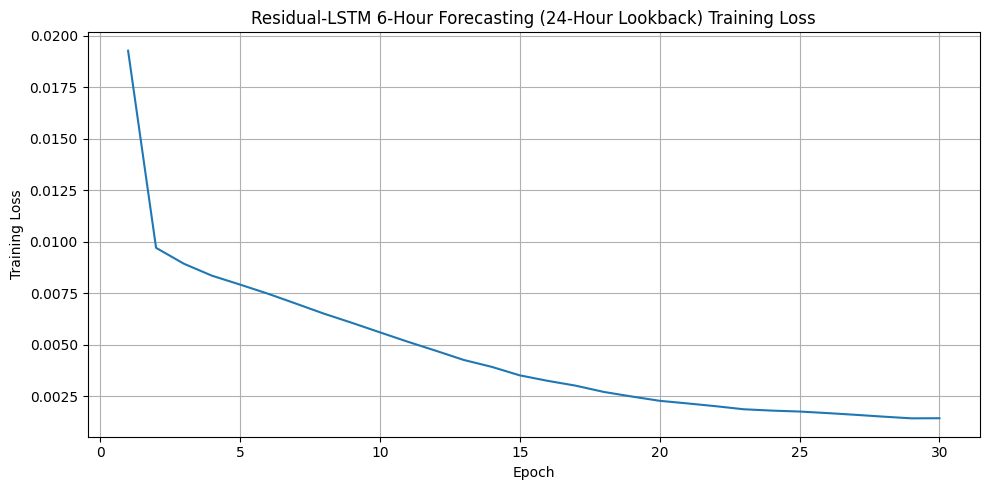

In [121]:
# Plot training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        EPOCHS_RESIDUAL_6H_24LB + 1
    ),
    training_losses_residual_6h_24lb
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.title(
    "Residual-LSTM 6-Hour Forecasting "
    "(24-Hour Lookback) Training Loss"
)

plt.grid(True)

plt.tight_layout()

plt.show()

In [122]:
# Generate 2025 predictions

model_residual_6h_24lb.eval()

predictions_residual_6h_24lb_scaled = []


with torch.no_grad():

    for X_batch, _ in test_loader_residual_6h_24lb:

        X_batch = X_batch.to(device)


        batch_predictions = model_residual_6h_24lb(
            X_batch
        )


        predictions_residual_6h_24lb_scaled.append(
            batch_predictions.cpu().numpy()
        )


predictions_residual_6h_24lb_scaled = np.concatenate(
    predictions_residual_6h_24lb_scaled,
    axis=0
)


print(
    "Prediction shape:",
    predictions_residual_6h_24lb_scaled.shape
)

Prediction shape: (8755, 6)


In [123]:
# Convert predictions back to MW

predictions_residual_6h_24lb_mw = (
    target_scaler_residual_6h_24lb.inverse_transform(
        predictions_residual_6h_24lb_scaled.reshape(-1, 1)
    )
    .reshape(
        predictions_residual_6h_24lb_scaled.shape
    )
)


# Convert actual values back to MW

actuals_residual_6h_24lb_mw = (
    target_scaler_residual_6h_24lb.inverse_transform(
        y_test_seq_residual_6h_24lb.reshape(-1, 1)
    )
    .reshape(
        y_test_seq_residual_6h_24lb.shape
    )
)


print(
    "Prediction shape:",
    predictions_residual_6h_24lb_mw.shape
)

print(
    "Actual shape:",
    actuals_residual_6h_24lb_mw.shape
)


print(
    "\nPredicted MW range:"
)

print(
    f"{predictions_residual_6h_24lb_mw.min():.4f}"
    f" → "
    f"{predictions_residual_6h_24lb_mw.max():.4f}"
)


print(
    "\nActual MW range:"
)

print(
    f"{actuals_residual_6h_24lb_mw.min():.4f}"
    f" → "
    f"{actuals_residual_6h_24lb_mw.max():.4f}"
)

Prediction shape: (8755, 6)
Actual shape: (8755, 6)

Predicted MW range:
1041.5753 → 29915.9785

Actual MW range:
168.6518 → 28264.5020


In [124]:
# Overall 6-hour forecasting metrics

actuals_residual_6h_24lb_flat = (
    actuals_residual_6h_24lb_mw.flatten()
)

predictions_residual_6h_24lb_flat = (
    predictions_residual_6h_24lb_mw.flatten()
)


mae_residual_6h_24lb = mean_absolute_error(
    actuals_residual_6h_24lb_flat,
    predictions_residual_6h_24lb_flat
)


rmse_residual_6h_24lb = np.sqrt(
    mean_squared_error(
        actuals_residual_6h_24lb_flat,
        predictions_residual_6h_24lb_flat
    )
)


r2_residual_6h_24lb = r2_score(
    actuals_residual_6h_24lb_flat,
    predictions_residual_6h_24lb_flat
)


mape_residual_6h_24lb = np.mean(
    np.abs(
        (
            actuals_residual_6h_24lb_flat
            - predictions_residual_6h_24lb_flat
        )
        / actuals_residual_6h_24lb_flat
    )
) * 100


print("===== IMPROVED RESIDUAL-LSTM 6-HOUR RESULTS =====")

print(
    f"MAE  : {mae_residual_6h_24lb:.2f} MW"
)

print(
    f"RMSE : {rmse_residual_6h_24lb:.2f} MW"
)

print(
    f"R²   : {r2_residual_6h_24lb:.4f}"
)

print(
    f"MAPE : {mape_residual_6h_24lb:.2f}%"
)

===== IMPROVED RESIDUAL-LSTM 6-HOUR RESULTS =====
MAE  : 2617.80 MW
RMSE : 3565.92 MW
R²   : 0.7262
MAPE : 30.95%


In [125]:
# Metrics for t+1 through t+6

residual_6h_24lb_horizon_results = []


for horizon_index in range(
    FORECAST_HORIZON_RESIDUAL_6H_24LB
):

    actual_horizon = (
        actuals_residual_6h_24lb_mw[
            :, horizon_index
        ]
    )

    predicted_horizon = (
        predictions_residual_6h_24lb_mw[
            :, horizon_index
        ]
    )


    mae_horizon = mean_absolute_error(
        actual_horizon,
        predicted_horizon
    )


    rmse_horizon = np.sqrt(
        mean_squared_error(
            actual_horizon,
            predicted_horizon
        )
    )


    r2_horizon = r2_score(
        actual_horizon,
        predicted_horizon
    )


    mape_horizon = np.mean(
        np.abs(
            (
                actual_horizon
                - predicted_horizon
            )
            / actual_horizon
        )
    ) * 100


    residual_6h_24lb_horizon_results.append(
        {
            "Horizon": f"t+{horizon_index + 1}",
            "MAE_MW": mae_horizon,
            "RMSE_MW": rmse_horizon,
            "R2": r2_horizon,
            "MAPE_percent": mape_horizon
        }
    )


residual_6h_24lb_horizon_df = pd.DataFrame(
    residual_6h_24lb_horizon_results
)


print(
    residual_6h_24lb_horizon_df.to_string(
        index=False
    )
)

Horizon      MAE_MW     RMSE_MW       R2  MAPE_percent
    t+1 1149.817505 1489.125834 0.952238     15.815562
    t+2 1925.927124 2488.835270 0.866588     23.594921
    t+3 2563.004150 3315.791610 0.763210     30.138292
    t+4 3018.904053 3908.534508 0.671016     35.009205
    t+5 3381.198975 4372.386991 0.588356     39.023746
    t+6 3667.977783 4742.800017 0.515738     42.141197


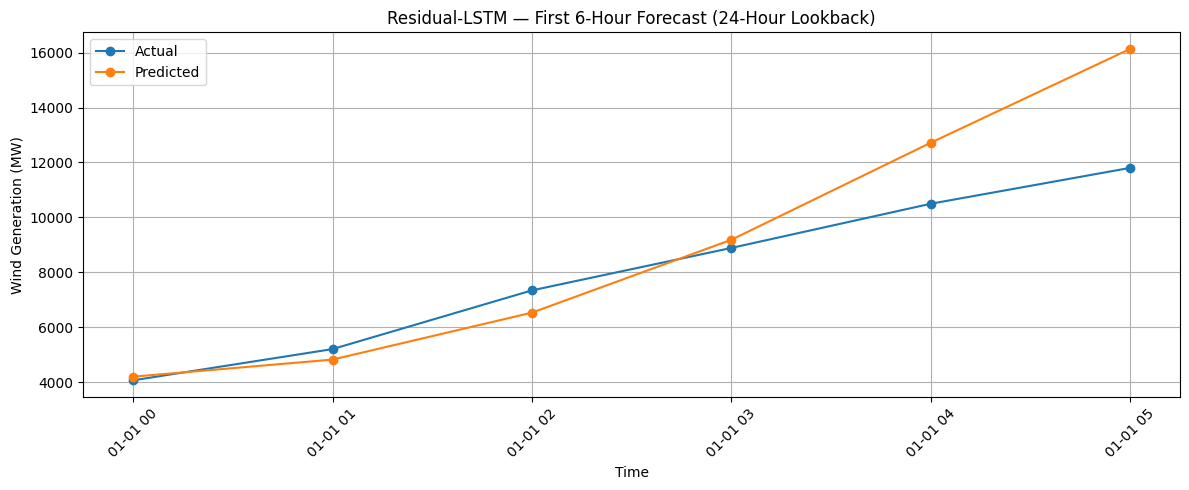

In [126]:
# First 6-hour forecast

first_forecast_timestamp_residual_6h_24lb = df.loc[
    test_start_idx,
    "Datetime_UTC"
]


forecast_timestamps_residual_6h_24lb = pd.date_range(
    start=first_forecast_timestamp_residual_6h_24lb,
    periods=FORECAST_HORIZON_RESIDUAL_6H_24LB,
    freq="h"
)


plt.figure(figsize=(12, 5))


plt.plot(
    forecast_timestamps_residual_6h_24lb,
    actuals_residual_6h_24lb_mw[0],
    marker="o",
    label="Actual"
)


plt.plot(
    forecast_timestamps_residual_6h_24lb,
    predictions_residual_6h_24lb_mw[0],
    marker="o",
    label="Predicted"
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Residual-LSTM — First 6-Hour Forecast "
    "(24-Hour Lookback)"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

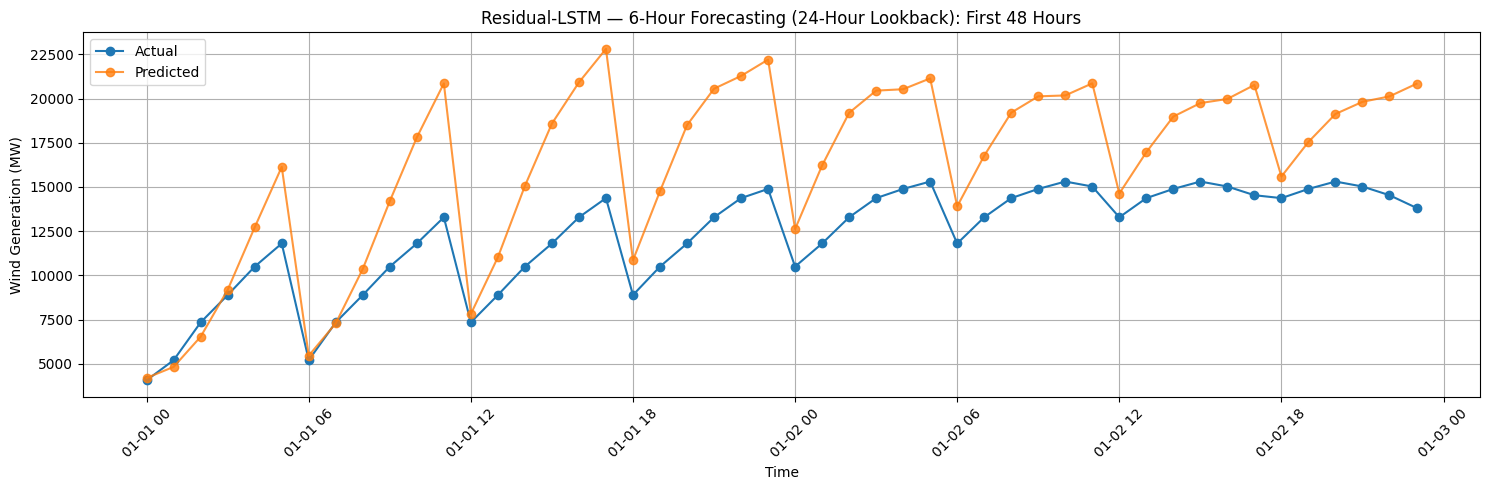

In [127]:
# First 48 hours using non-overlapping 6-hour forecasts

NUMBER_OF_48H_WINDOWS_RESIDUAL_6H_24LB = 8


actual_48h_residual_6h_24lb = (
    actuals_residual_6h_24lb_mw[
        :NUMBER_OF_48H_WINDOWS_RESIDUAL_6H_24LB
    ].reshape(-1)
)


predicted_48h_residual_6h_24lb = (
    predictions_residual_6h_24lb_mw[
        :NUMBER_OF_48H_WINDOWS_RESIDUAL_6H_24LB
    ].reshape(-1)
)


timestamps_48h_residual_6h_24lb = pd.date_range(
    start=df.loc[
        test_start_idx,
        "Datetime_UTC"
    ],
    periods=48,
    freq="h"
)


plt.figure(figsize=(15, 5))


plt.plot(
    timestamps_48h_residual_6h_24lb,
    actual_48h_residual_6h_24lb,
    marker="o",
    label="Actual"
)


plt.plot(
    timestamps_48h_residual_6h_24lb,
    predicted_48h_residual_6h_24lb,
    marker="o",
    label="Predicted",
    alpha=0.8
)


plt.xlabel("Time")

plt.ylabel(
    "Wind Generation (MW)"
)

plt.title(
    "Residual-LSTM — 6-Hour Forecasting "
    "(24-Hour Lookback): First 48 Hours"
)

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()